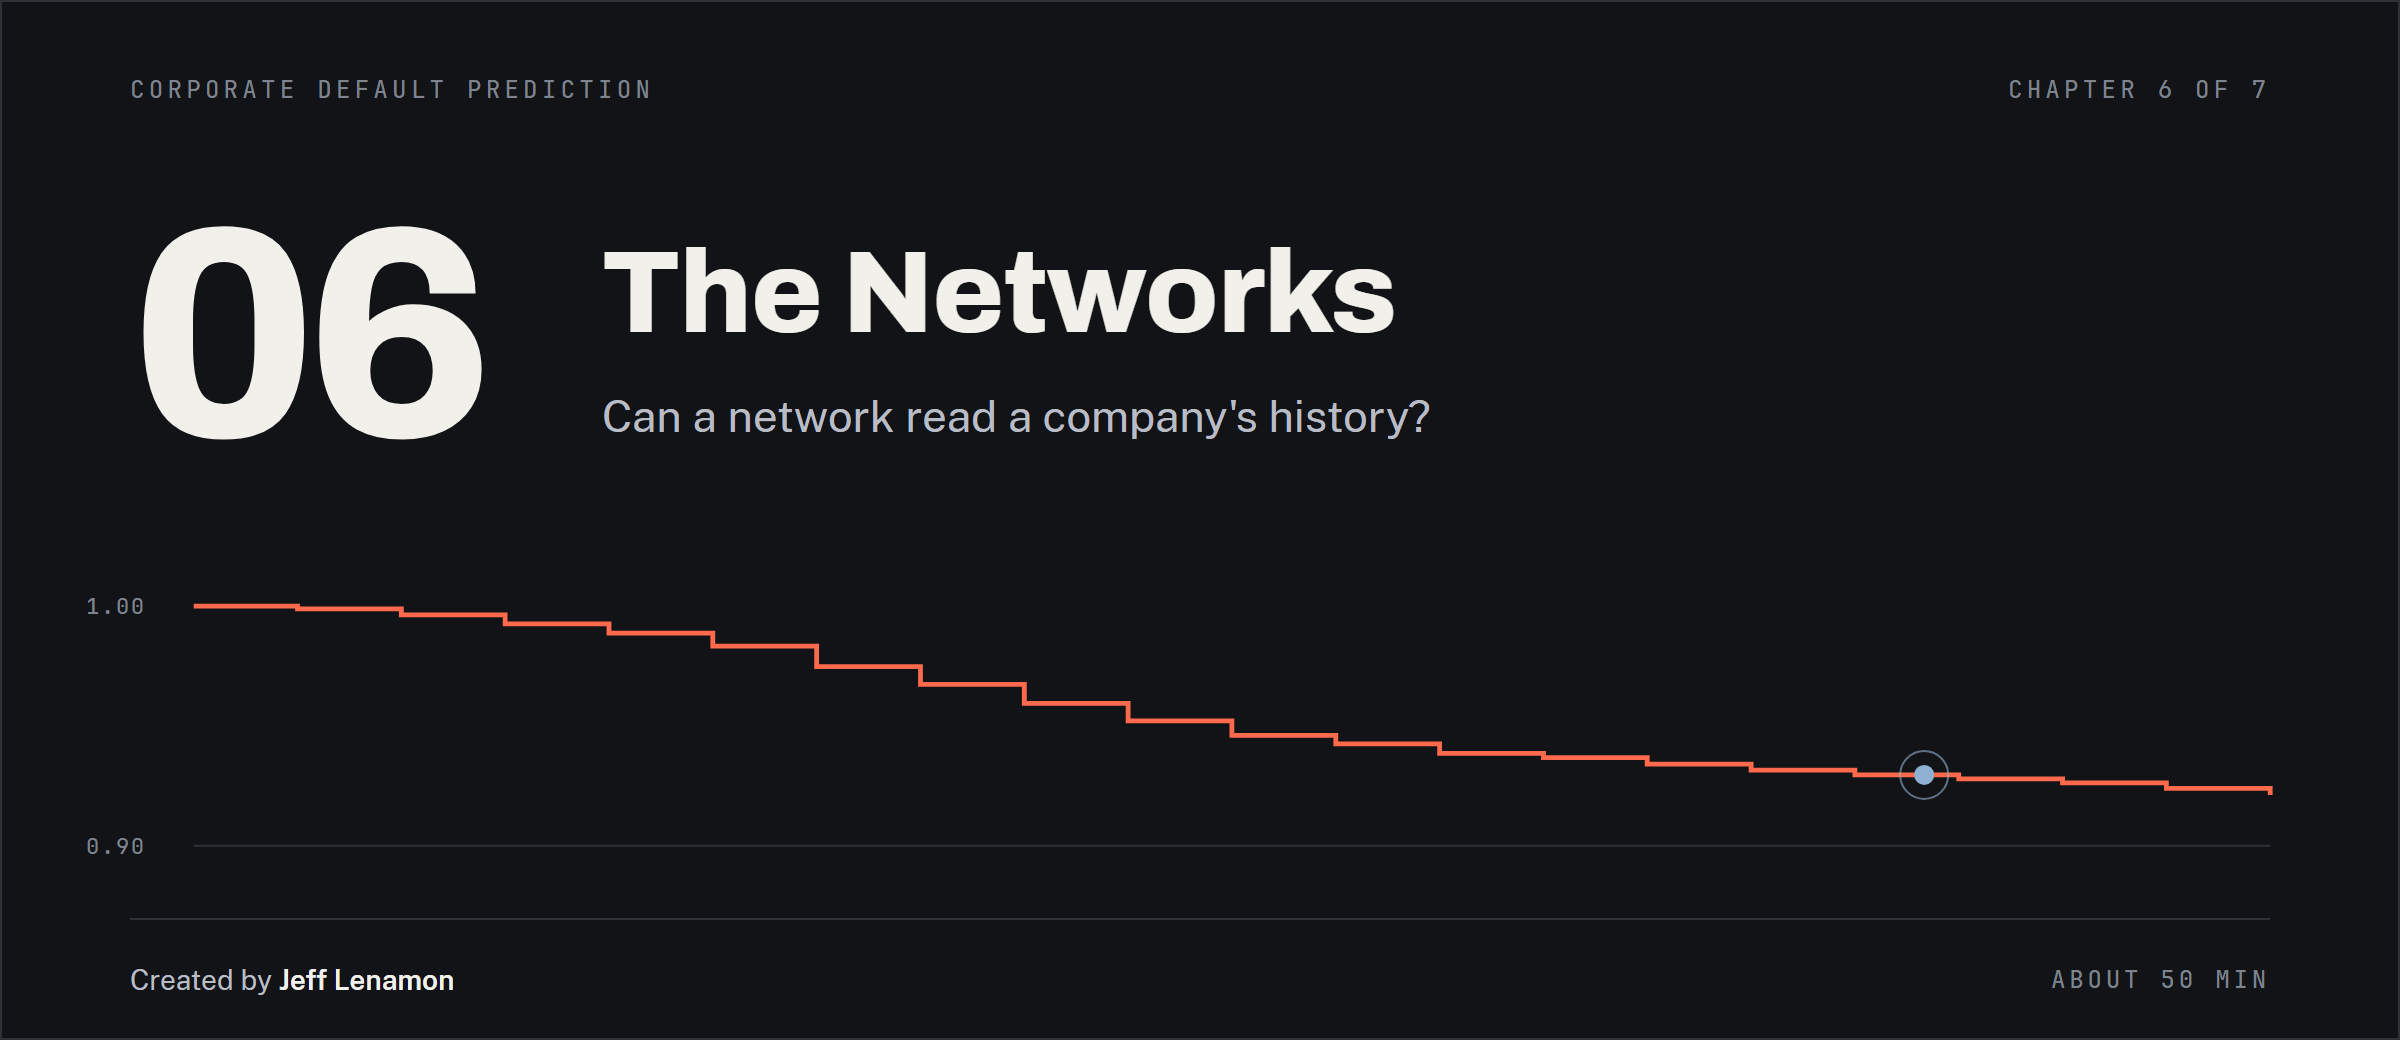

# Chapter 6: The Networks

What a neural network needs before it can read a ratio, what it makes of a company's last five years, and what it adds to the trees.

> This casebook is educational content created in a personal capacity

> Nothing here is investment advice or a recommendation to buy or sell any security

> The data is a public research dataset with anonymised company names

## The Question

Chapter 5 gave the trees a company's history as extra columns, and the ranking got worse.
Perhaps the columns were the wrong way to tell the story.

A network can be handed the years themselves, in order, and left to find the pattern.
Can a network read a company's history?

## What You Will Learn

By the end you can:

- prepare inputs for a network, and say why a tree did not need it;
- train a small network so that the same seed gives the same model;
- stop training early without touching the validation year;
- turn a panel into sequences with a mask for the missing years;
- read three hazards as a term structure of default probability.

## What You Need

Chapter 3, which wrote the `features` table, and Chapters 4 and 5, which wrote the out-of-fold scores of the first five rungs.
Chapter 5 also chose the tree model this chapter blends with.

The networks run on the processor, with no graphics card.
The slow cells say so.

The chapter adds two rungs to the table of scores, and the settings of the network and of the blend to the record of how each model is built.

## Your Route

![Your route through Chapter 6: 1 Setting Up, 6 minutes; 2 What a Network Needs That a Tree Does Not, 3 minutes; 3 A Tabular Network, 10 minutes; 4 From Rows to Sequences, 3 minutes; 5 A Recurrent Network, 4 minutes; 6 One Model, Three Horizons, 3 minutes; 7 Trees Against Networks, 4 minutes; 8 Blending, 2 minutes; 9 The Ladder So Far, 5 minutes.](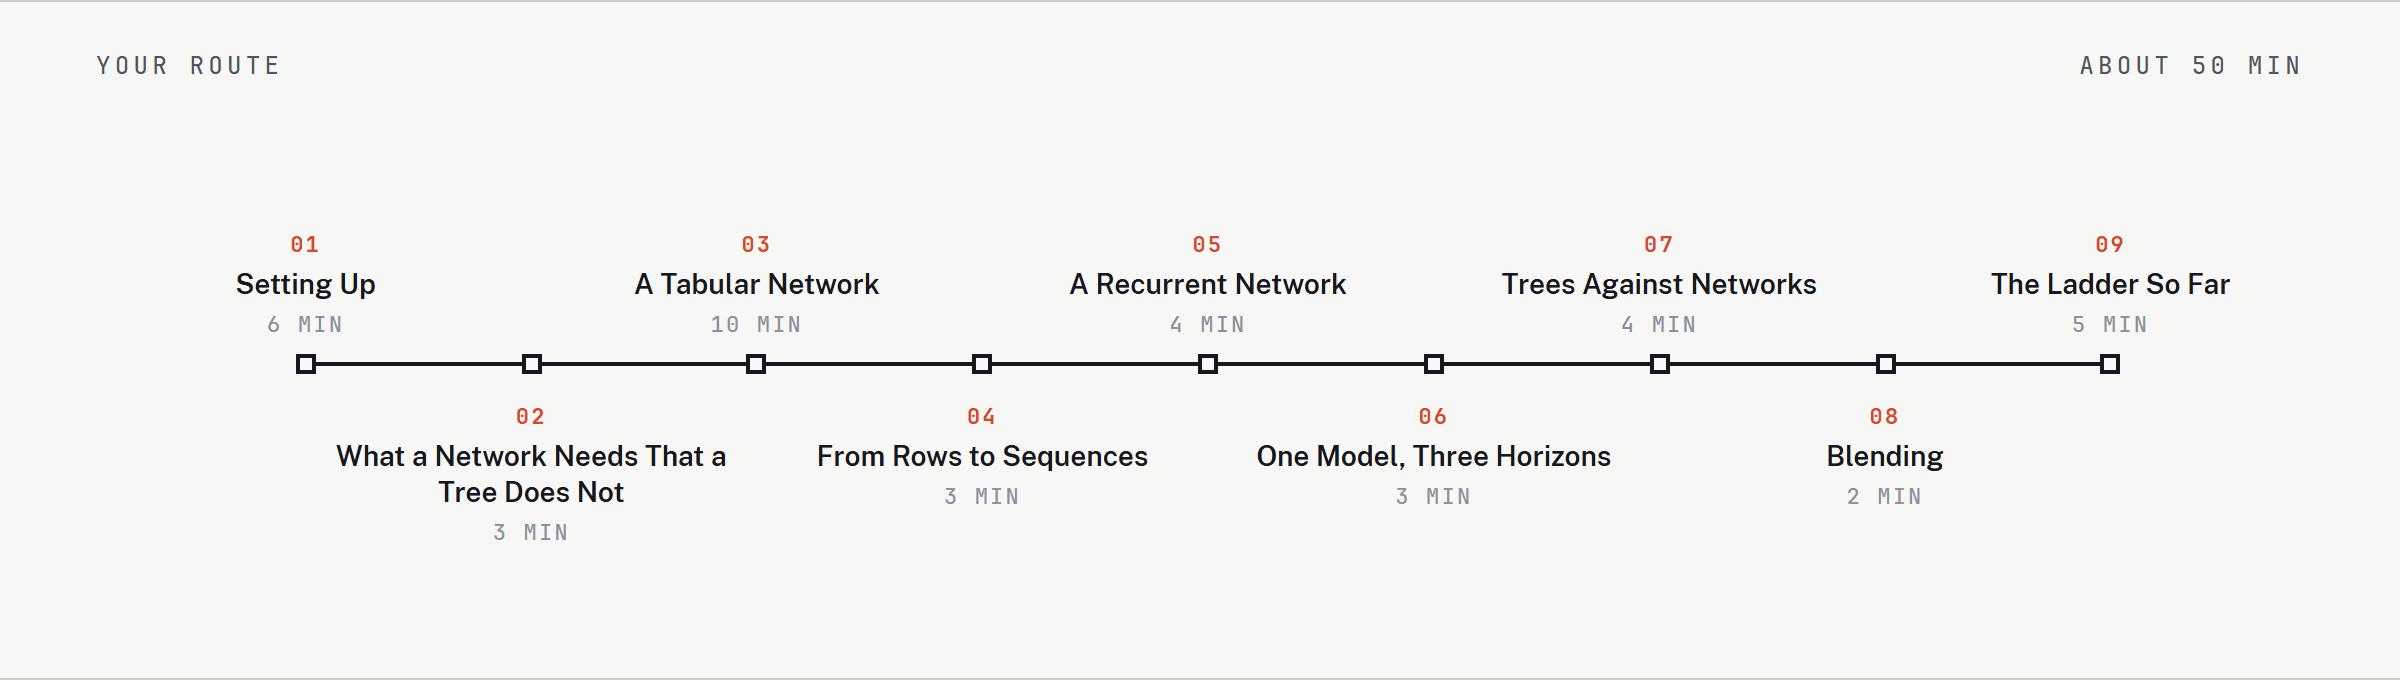)

**Time.** About 43 minutes to read and run, then about 9 for Your Turn.

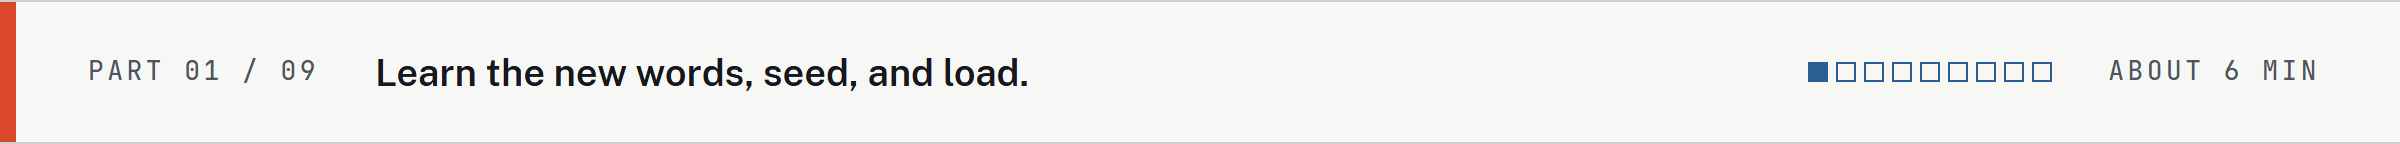

# Setting Up

Make sure the Jupyter kernel `corp-default` is selected before you run a cell.
If it is not in the list, or an import fails, the [Quick Start](../README.md#quick-start) shows how to register it and refresh the list.

## The Data Dictionary

The chapter reads `features` and the out-of-fold scores of Chapters 4 and 5.
Every network is offered the same 24 ratios as the tree model that goes forward.

The chapter builds three things from them.

| Name | What it holds |
| --- | --- |
| **Transformed ratio** | A ratio moved onto a bell-shaped scale by its rank among the training rows |
| **Blank flag** | One where a ratio could not be computed, zero elsewhere |
| **Hazard target** | For each of three years ahead: did the final filing fall in that year, given that it had not come sooner |

Eight words describe a network and its training.

| Term | What it means |
| --- | --- |
| **Layer** | A set of weighted sums of the inputs, each passed through a simple bend |
| **Epoch** | One pass of the training rows through the network |
| **Batch** | The handful of rows the network sees before each small correction |
| **Learning rate** | The size of each correction to the weights |
| **Dropout** | Switching off a random share of a layer during training, so that no single unit is relied on |
| **Weight decay** | A steady pull of every weight towards zero |
| **Early stopping** | Ending training when rows set aside stop being predicted better |
| **Seed** | The number that fixes every random choice, so that a run can be repeated |

Q. What does the chapter need before it starts?

In [1]:
import copy
import random
from collections.abc import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from joblib import Parallel, delayed
from matplotlib.ticker import FuncFormatter, MaxNLocator, MultipleLocator, PercentFormatter
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import QuantileTransformer
from torch import nn

from corp_default import store, viz
from corp_default.evaluate import KEYS, SEED, fold_table, paired_table, scoreboard
from corp_default.features import FAMILIES
from corp_default.metrics import wilson_interval, within_year_percentile
from corp_default.nets import hazard_loss, predict
from corp_default.splits import DEV_END, FOLD_YEARS, HORIZON, development, walk_forward_folds

store.open_chapter(6)
viz.use_house_style()
SOURCE = "Lombardo et al. (2022), Kaggle copy"
OOF_SOURCE = f"{SOURCE}; out-of-fold rows, {FOLD_YEARS[0]} to {FOLD_YEARS[-1]}"
NETWORKS = viz.MODEL_COLORS["networks"]

features = store.load_frame("features")
earlier = store.load_frame("oof_scores")
frozen = store.load_json("frozen")

**Reading.** The table of Chapter 3, the scores of Chapters 4 and 5, and the record of each model are in memory.
`store.put` carries a number from a cell into the text, so no number in this chapter is typed by hand.

A network starts from random weights, sees its rows in a random order, and drops units at random.
The next function fixes all of that.

In [2]:
# taught: corp_default.nets.seed_everything
def seed_everything(seed: int = 42) -> None:
    """Seed Python, NumPy, and PyTorch, and make PyTorch repeat itself.

    One thread, because a sum split over several threads can round differently on another machine.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)
    torch.set_num_threads(1)

**Reading.** Three libraries draw random numbers, and each gets the seed.
The last two lines ask PyTorch to give the same answer on every run, at the price of some speed.

Q. What do the scores of the earlier chapters look like?

In [3]:
earlier.head()

,company_name,year,target,score,pct,model
0,C_1,2005,0,-2.878107,0.550540,Altman Z
1,C_2,2005,0,-2.412993,0.610324,Altman Z
2,C_3,2005,0,-6.339636,0.217767,Altman Z
3,C_4,2005,0,-1.971397,0.674670,Altman Z
4,C_6,2005,0,-0.554995,0.818968,Altman Z


**Reading.** Each row is one firm-year scored by one model: the score, and its percentile within the year.

Q. How large are the tables, and which tree model goes forward?

In [4]:
RATIOS = [name for members in FAMILIES.values() for name in members]
NETWORK, BLEND = "Network, all ratios", "Blend, trees and network"
NEW = [NETWORK, BLEND]
# A second run of this chapter finds its own two rungs in the file, and sets them aside.
earlier = earlier.loc[~earlier["model"].isin(NEW)].reset_index(drop=True)
ladder = {
    name: part.drop(columns="model").reset_index(drop=True)
    for name, part in earlier.groupby("model", sort=False)
}
TREES = next(name for name, spec in frozen.items() if spec.get("forward"))

dev = development(features).reset_index(drop=True)
folds = walk_forward_folds(dev)
last = folds[-1]
train_last, valid_last = dev.loc[last.train], dev.loc[last.valid]
oof_rows = dev.loc[np.concatenate([fold.valid for fold in folds]), [*KEYS, "target"]].reset_index(
    drop=True
)
# Every rung is scored on the same rows in the same order. Checked here.
assert all((oof[KEYS] == oof_rows[KEYS]).all().all() for oof in ladder.values())

store.put("n_ratios", len(RATIOS))
store.put("n_folds", len(folds))
store.put("n_rungs", len(ladder))
store.put("trees_name", TREES)

print(features.shape, dev.shape, TREES)
earlier.info()

(72393, 73) (55524, 73) All ratios, trees
<class 'pandas.DataFrame'>
RangeIndex: 133945 entries, 0 to 133944
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   company_name  133945 non-null  str    
 1   year          133945 non-null  int64  
 2   target        133945 non-null  int64  
 3   score         133945 non-null  float64
 4   pct           133945 non-null  float64
 5   model         133945 non-null  str    
dtypes: float64(2), int64(2), str(2)
memory usage: 6.1 MB


**Reading.** The table of scores holds the same out-of-fold rows once for each of the 5 rungs so far.
The tree model that goes forward is "All ratios, trees", the fourth rung.

Q. What do the ratios look like to a model that adds its inputs up?

In [5]:
spread = dev[RATIOS].describe().T
# The reading says one ratio has blanks in more than a tenth of its rows. Checked here.
blank_share = dev[RATIOS].isna().mean()
assert (blank_share > 0.1).sum() == 1

store.put("widest_ratio", (spread["max"] - spread["min"]).idxmax())
store.put("widest_range", (spread["max"] - spread["min"]).max())
store.put("blankest_ratio", blank_share.idxmax())
store.put("blankest_share", blank_share.max())

spread.round(3)

,count,mean,std,min,25%,50%,75%,max
liabilities_to_assets,55524.0,1.662,42.113,0.000,0.288,0.492,0.696,6324.000
lt_debt_to_assets,55524.0,0.211,1.643,0.000,0.000,0.088,0.275,308.800
book_equity_to_assets,55524.0,-0.662,42.113,-6323.000,0.304,0.508,0.712,1.000
debt_to_ebitda,39622.0,3.427,49.911,0.000,0.022,1.040,2.737,7629.465
no_lt_debt,55524.0,0.263,0.440,0.000,0.000,0.000,1.000,1.000
roa,55524.0,-0.526,12.123,-1515.000,-0.130,0.018,0.068,244.833
ebit_to_assets,55524.0,-0.341,8.498,-1241.000,-0.080,0.049,0.107,35.917
ebitda_to_assets,55524.0,-0.279,8.162,-1224.000,-0.031,0.090,0.153,35.917
net_margin,55524.0,-7.414,205.728,-29319.000,-0.157,0.016,0.069,1024.000
ebitda_margin,55524.0,-5.814,167.485,-29325.700,-0.033,0.081,0.166,358.211


**Reading.** The ratios live on very different scales: `market_to_book_assets` alone spans 69,277 from its lowest value to its highest.
One ratio, `debt_to_ebitda`, is blank in 29% of rows.

**Next, why that matters to a network and not to a tree.**

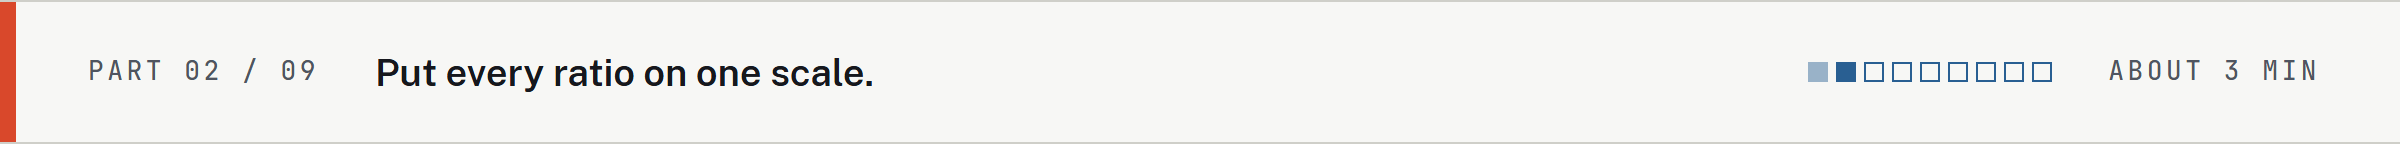

# What a Network Needs That a Tree Does Not

A tree asks only whether a ratio is above or below a number.
Stretch the ratio's scale and the tree asks the same question at a different number.

A network multiplies each input by a weight and adds the results up.
An input a thousand times larger than the rest gets a thousand times the say, and a blank cannot be multiplied at all.

So the inputs are prepared in two steps.
A **quantile transform** replaces each value by its rank among the training rows and reads that rank off a bell curve.

A **blank flag** then records where a value was missing, and the blank itself becomes zero, the middle of the bell.

Q. How is the transform fitted, and what does it do to a ratio?

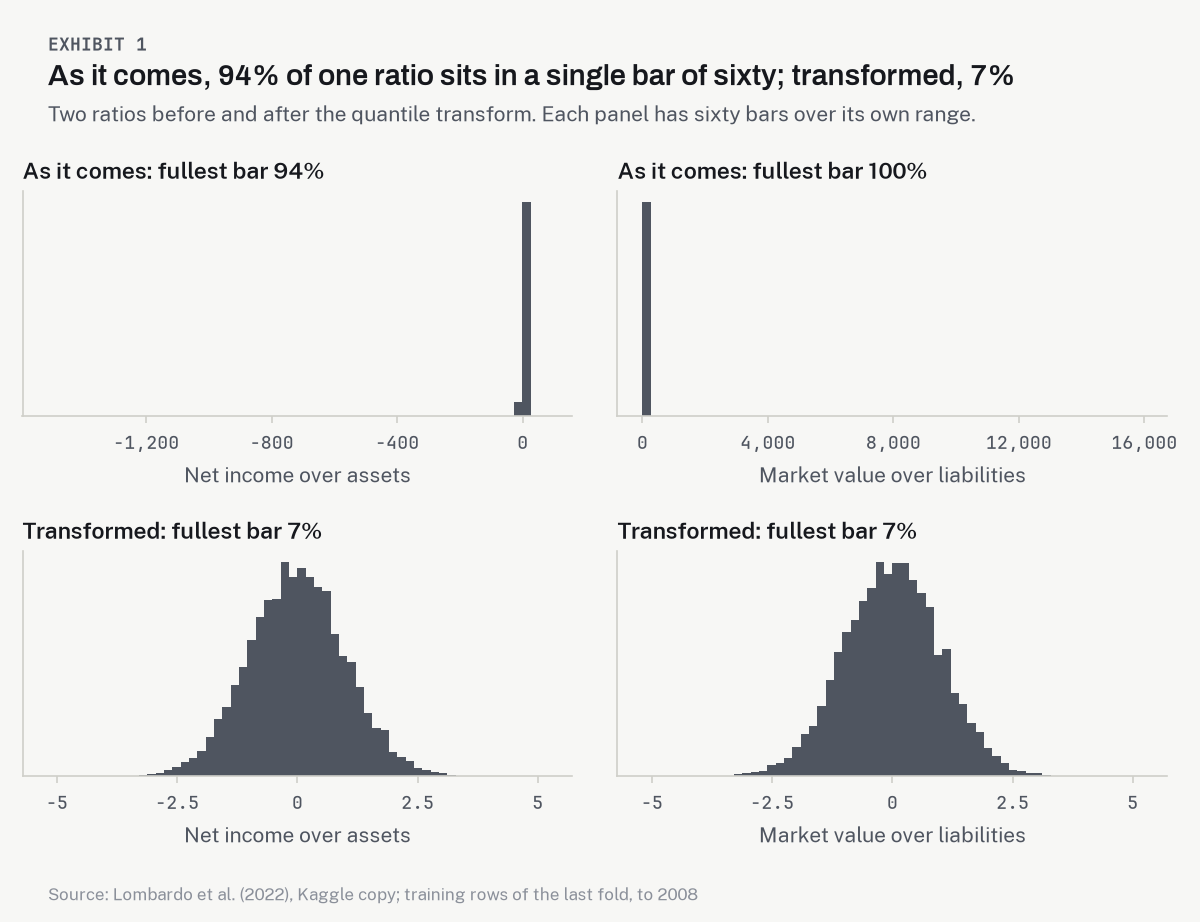

In [6]:
def fit_inputs(train: pd.DataFrame, columns: list[str], transform: bool = True) -> Callable:
    """Network inputs from `columns`, fitted on `train` only.

    transform=True: each ratio on a bell scale by its training rank, blanks at zero, a flag for
    each ratio that has blanks. transform=False: the ratios as they come, blanks at the median.
    """
    if not transform:
        medians = train[columns].median()
        return lambda rows: rows[columns].fillna(medians)
    scale = QuantileTransformer(n_quantiles=1000, output_distribution="normal", random_state=SEED)
    scale.fit(train[columns])
    blanks = [name for name in columns if train[name].isna().any()]

    def prepare(rows: pd.DataFrame) -> pd.DataFrame:
        bell = pd.DataFrame(scale.transform(rows[columns]), columns=columns, index=rows.index)
        flags = {f"{name}_blank": rows[name].isna().astype(float) for name in blanks}
        return bell.fillna(0.0).assign(**flags)

    return prepare


def tallest_bar(values: pd.Series, bars: int = 60) -> float:
    """The share of values in the fullest of `bars` equal bars."""
    counts, _ = np.histogram(values.dropna(), bins=bars)
    return counts.max() / counts.sum()


SHOWN = {"roa": "Net income over assets", "mve_to_liabilities": "Market value over liabilities"}
prepare_last = fit_inputs(train_last, RATIOS)
inputs_last = prepare_last(train_last)

fig, axes = plt.subplots(2, len(SHOWN), figsize=(viz.EXHIBIT_WIDTH_IN, 4.8))
for column, (name, label) in enumerate(SHOWN.items()):
    versions = [(train_last[name], "As it comes"), (inputs_last[name], "Transformed")]
    for ax, (values, when) in zip(axes[:, column], versions):
        ax.hist(values.dropna(), bins=60, color=viz.SLATE)
        ax.set_title(f"{when}: fullest bar {tallest_bar(values):.0%}")
        ax.set_xlabel(label)
        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.xaxis.set_major_formatter(FuncFormatter(viz.plain_number))
        ax.set_yticks([])
        ax.grid(visible=False)

store.put("n_inputs", inputs_last.shape[1])
# The reading says one ratio has blanks in these rows. Checked here.
assert inputs_last.shape[1] - len(RATIOS) == 1
store.put("raw_tallest", tallest_bar(train_last["roa"]))
store.put("bell_tallest", tallest_bar(inputs_last["roa"]))
# The reading says the transformed ratios stay within a few units of zero. Checked here.
assert inputs_last[RATIOS].abs().max().max() < 6

viz.exhibit(
    fig,
    f"As it comes, {tallest_bar(train_last['roa']):.0%} of one ratio sits in a single bar of sixty; "
    f"transformed, {tallest_bar(inputs_last['roa']):.0%}",
    "Two ratios before and after the quantile transform. Each panel has sixty bars over its own range.",
    f"{SOURCE}; training rows of the last fold, to {train_last['year'].max()}",
)

**Reading.** In Exhibit 1 the untransformed ratio puts 94% of its rows in one bar, because a few extreme values set the scale.
After the transform the same rows spread over a bell, and every ratio stays within a few units of zero.

The network now has 25 inputs: the 24 ratios, and a blank flag for the one ratio that has blanks in these rows.
Whether the preparation matters is tested in the next part, once there is a network to test it on.

**Check.** The transform is fitted on a fold's training rows and then applied to its validation rows. What would go wrong if it were fitted on all the rows at once?

<details>
<summary>Show the answer</summary>

A rank among all rows knows where the later years sit.
The model would be handed a little of the future in every input, which is the leak Chapter 4 closed for the clipping bounds.

</details>

**Next, the network itself.**

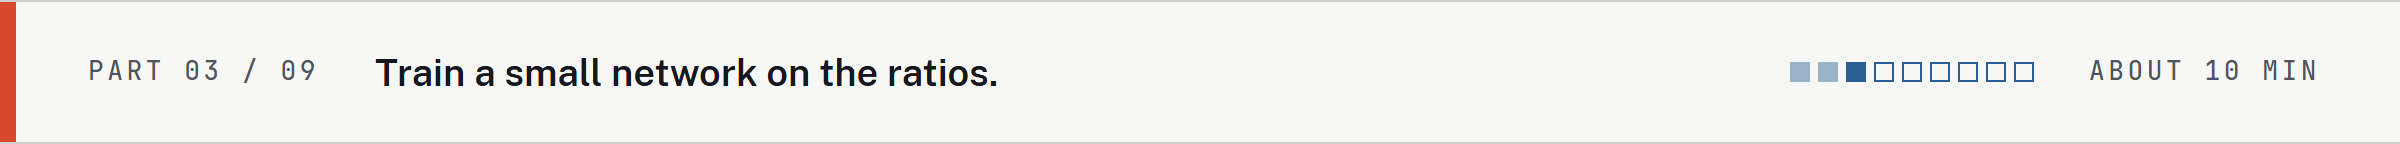

# A Tabular Network

The first network reads one row at a time, as the trees did.
It has two hidden layers, and its output is one number for each row, a score that is turned into a probability when the model is asked to predict.

In [7]:
# taught: corp_default.nets.TabularNet
class TabularNet(nn.Module):
    """Two hidden layers with dropout, and one logit for each row."""

    def __init__(self, n_inputs: int, hidden: int = 64, dropout: float = 0.2):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x).squeeze(-1)

**Reading.** Each `Linear` layer is a set of weighted sums, and each `ReLU` is the bend: it passes a positive sum and stops a negative one.
`Dropout` switches off a random fifth of the units while the network trains.

Training is one loop, and it is the same loop for every network in the chapter.

In [8]:
# taught: corp_default.nets.train_net
def train_net(
    model: nn.Module,
    train: tuple[torch.Tensor, ...],
    valid: tuple[torch.Tensor, ...] | None,
    *,
    epochs: int,
    lr: float,
    weight_decay: float,
    patience: int,
    seed: int,
    batch_size: int = 256,
) -> dict:
    """Fit `model` with AdamW, stopping when the loss on `valid` has not improved for `patience` epochs.

    `train` and `valid` are tuples of tensors: the model's inputs, then targets, then observed.
    With `valid` None every epoch runs and the last state is the best one.
    The model is left holding its best state. Returns that state, its epoch, and the loss history.
    """
    *inputs, targets, observed = train
    torch.manual_seed(seed)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    history, best_loss, best_epoch, best_state = [], float("inf"), 0, None
    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(targets))
        total = 0.0
        for start in range(0, len(order), batch_size):
            rows = order[start : start + batch_size]
            loss = hazard_loss(
                model(*(part[rows] for part in inputs)), targets[rows], observed[rows]
            )
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * observed[rows].sum().item()
        valid_loss = float("nan")
        if valid is not None:
            model.eval()
            with torch.no_grad():
                valid_loss = hazard_loss(model(*valid[:-2]), *valid[-2:]).item()
        history.append(
            {"epoch": epoch, "train_loss": total / observed.sum().item(), "valid_loss": valid_loss}
        )
        if valid is None or valid_loss < best_loss:
            best_loss, best_epoch, best_state = valid_loss, epoch, copy.deepcopy(model.state_dict())
        elif epoch - best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    return {"state": best_state, "best_epoch": best_epoch, "history": pd.DataFrame(history)}

**Reading.** In each epoch the rows are shuffled and fed through in batches, and after each batch the weights move a little against the loss.
After each epoch the loop measures the loss on rows it did not train on, and it stops once that loss has gone `patience` epochs without a new low.

The rows it stops on cannot be the validation year, or the validation year would have helped to build the model.
So each fold sets aside its own last two training years for stopping.

That costs the fit its two most recent years, so the stopped fit is used for one thing only: the number of epochs.
A second fit then runs on every training row for that many epochs.

A network's score also moves with its seed, as Chapter 5 found for trees.
So each fold is fitted with three seeds and the three sets of probabilities are averaged, a **seed ensemble**.

The settings below are plain ones, a first guess that a small search checks later in this part.

**Predict 1.** The trees scored 0.776 on these ratios. Will the network rank the same rows better, worse, or about the same?

Q. What does the network score on the walk-forward?

In [9]:
SETTINGS = {"epochs": 60, "lr": 1e-3, "weight_decay": 1e-2, "patience": 5}
SEEDS = (SEED, SEED + 1, SEED + 2)
DROPOUT = 0.2
STOP_YEARS = 2  # the last training years of a fold, set aside to stop on


def tensor(values) -> torch.Tensor:
    return torch.tensor(np.asarray(values, dtype=np.float32))


def stop_rows(train: pd.DataFrame) -> torch.Tensor:
    """True for the rows of a fold's last STOP_YEARS training years."""
    return torch.tensor((train["year"] > train["year"].max() - STOP_YEARS).to_numpy())


def fit_net(
    make_model: Callable,
    train: tuple,
    stop: torch.Tensor,
    valid_inputs: tuple,
    seed: int,
    lr: float,
):
    """A stopped fit to choose the epochs, then a fit on every training row for that many."""
    settings = {**SETTINGS, "lr": lr}
    seed_everything(seed)
    early = tuple(part[~stop] for part in train)
    held = tuple(part[stop] for part in train)
    stopped = train_net(make_model(), early, held, seed=seed, **settings)
    seed_everything(seed)
    model = make_model()
    train_net(model, train, None, seed=seed, **{**settings, "epochs": stopped["best_epoch"]})
    return {
        "scores": predict(model, *valid_inputs),
        "epochs": stopped["best_epoch"],
        "history": stopped["history"],
    }


def tabular_fit(
    fold, seed: int, transform: bool = True, lr: float = SETTINGS["lr"], dropout: float = DROPOUT
) -> dict:
    """One tabular network for one fold and one seed."""
    train, valid = dev.loc[fold.train], dev.loc[fold.valid]
    prepare = fit_inputs(train, RATIOS, transform)
    x = tensor(prepare(train))
    data = (x, tensor(train["target"]), torch.ones(len(train)))
    make_model = lambda: TabularNet(x.shape[1], dropout=dropout)
    return fit_net(make_model, data, stop_rows(train), (tensor(prepare(valid)),), seed, lr)


def side_by_side(fit: Callable, **more) -> pd.DataFrame:
    """Every fold with every seed, each fit in a process of its own. One row for each fit."""
    tasks = [(fold, seed) for fold in folds for seed in SEEDS]
    done = Parallel(n_jobs=-1, max_nbytes=None)(
        delayed(fit)(fold, seed, **more) for fold, seed in tasks
    )
    return pd.DataFrame(done).assign(
        fold=[fold.year for fold, _ in tasks], seed=[seed for _, seed in tasks]
    )


def seed_mean(fits: pd.DataFrame) -> np.ndarray:
    """The out-of-fold scores, fold after fold, each the mean over its seeds."""
    return np.concatenate(
        [np.mean(np.stack(list(part["scores"])), axis=0) for _, part in fits.groupby("fold")]
    )


def as_oof(scores: np.ndarray) -> pd.DataFrame:
    """A table of out-of-fold scores in the form the ladder keeps, ranked within each year."""
    oof = oof_rows.assign(score=scores)
    return oof.assign(pct=within_year_percentile(oof["score"], oof["year"]))


# This cell fits the network 21 times, twice each. It takes about a minute on a recent laptop.
plain_fits = side_by_side(tabular_fit)
tab_epochs = plain_fits.pivot(index="fold", columns="seed", values="epochs")

store.put("n_seeds", len(SEEDS))
store.put("stop_years", STOP_YEARS)
store.put("first_fold", folds[0].year)
store.put("first_fold_epochs", int(tab_epochs.loc[folds[0].year].max()))
store.put("most_epochs", int(tab_epochs.max().max()))
store.put("first_fold_rows", int((~stop_rows(dev.loc[folds[0].train])).sum()))

tab_epochs

seed,42,43,44
fold,,,
2005,1,1,1
2006,5,14,3
2007,2,7,7
2008,9,6,2
2009,5,10,2
2010,13,4,7
2011,13,7,9


**Reading.** The table shows the epochs each stopped fit chose.
In the fold of 2005 no seed chose more than 1: with two years set aside, the stopped fit there trains on 10,524 rows.

No fit in any fold wanted more than 14 epochs.

Q. What does training look like, epoch by epoch?

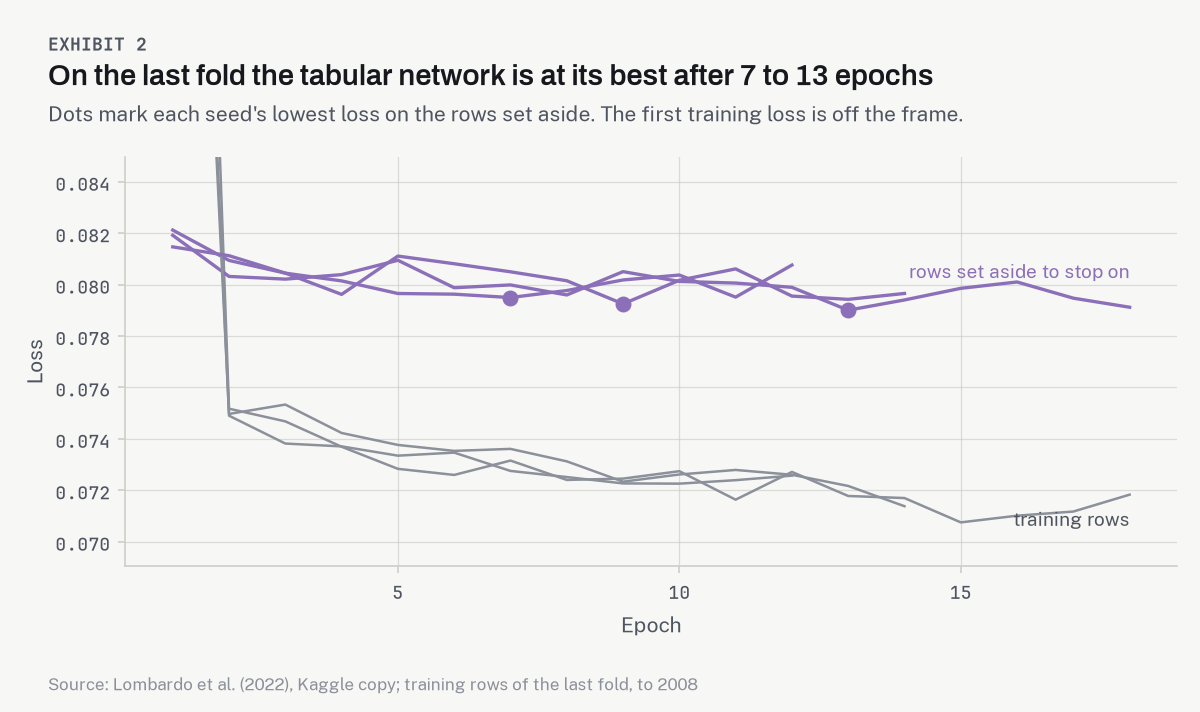

In [10]:
def learning_curves(fits: pd.DataFrame) -> plt.Figure:
    """Loss by epoch for each seed of the last fold: training rows, and the rows it stops on."""
    fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.4))
    histories = [
        fit["history"].set_index("epoch") for _, fit in fits.iterrows() if fit["fold"] == last.year
    ]
    chosen = fits.loc[fits["fold"] == last.year, "epochs"]
    for history, epochs in zip(histories, chosen):
        ax.plot(history["train_loss"], color=viz.MIST, linewidth=1.2)
        ax.plot(history["valid_loss"], color=NETWORKS, linewidth=1.6)
        ax.scatter(epochs, history.loc[epochs, "valid_loss"], s=44, color=NETWORKS, zorder=3)
    # The first epoch's training loss is far above the rest, so the frame is cut below it.
    low = min(history["train_loss"].min() for history in histories)
    high = max(history["valid_loss"].max() for history in histories)
    ax.set_ylim(low - 0.15 * (high - low), high + 0.25 * (high - low))
    longest = max(histories, key=len)
    ax.annotate("rows set aside to stop on", (len(longest), longest["valid_loss"].iloc[-1]),
                xytext=(0, 14), textcoords="offset points", color=NETWORKS, size=9, ha="right")  # fmt: skip
    ax.annotate("training rows", (len(longest), longest["train_loss"].iloc[-1]),
                xytext=(0, -15), textcoords="offset points", color=viz.SLATE, size=9, ha="right")  # fmt: skip
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.xaxis.set_major_locator(MultipleLocator(5))
    return fig


def last_fold_epochs(fits: pd.DataFrame) -> list[int]:
    return sorted(fits.loc[fits["fold"] == last.year, "epochs"])


tab_last = last_fold_epochs(plain_fits)
held_last = stop_rows(train_last).numpy()
# The reading says failures were more common in the years set aside. Checked here.
assert train_last.loc[held_last, "target"].mean() > train_last.loc[~held_last, "target"].mean()
store.put("tab_last_low", tab_last[0])
store.put("tab_last_high", tab_last[-1])

viz.exhibit(
    learning_curves(plain_fits),
    f"On the last fold the tabular network is at its best after {tab_last[0]} to {tab_last[-1]} epochs",
    "Dots mark each seed's lowest loss on the rows set aside. The first training loss is off the frame.",
    f"{SOURCE}; training rows of the last fold, to {train_last['year'].max()}",
)

**Reading.** In Exhibit 2 the loss on the training rows keeps falling, as it always will.
The loss on the rows set aside reaches its low between epochs 7 and 13 and falls no further: from there the network is learning its training rows and nothing more.

The two sets of lines sit at different heights because failures were more common in the years set aside.

The plain settings were a first guess, so a small **grid search** checks them.
It tries every pairing of three learning rates and two rates of dropout, six networks in all, each a seed ensemble on the seven folds.

The learning rate comes first because it is the setting a network is most sensitive to.
Early stopping gives a slower rate the extra epochs it needs.

The rule is written before the result, and it is the rule of Chapter 5: the highest mean average precision over the seven folds, each fold counting the same.

Q. Which of the six does the rule choose?

In [11]:
def mean_fold_ap(oof: pd.DataFrame) -> float:
    """Average precision in each validation year, averaged over the years."""
    by_year = oof.groupby("year").apply(
        lambda rows: average_precision_score(rows["target"], rows["score"]), include_groups=False
    )
    return by_year.mean()


PLAIN = (SETTINGS["lr"], DROPOUT)
GRID = [(lr, dropout) for lr in (3e-4, 1e-3, 3e-3) for dropout in (0.2, 0.4)]

# Five more walk-forwards like the first one, which is the grid's sixth. About two minutes.
grid_fits = {
    (lr, dropout): plain_fits
    if (lr, dropout) == PLAIN
    else side_by_side(tabular_fit, lr=lr, dropout=dropout)
    for lr, dropout in GRID
}
grid = pd.Series(
    {setting: mean_fold_ap(as_oof(seed_mean(fits))) for setting, fits in grid_fits.items()}
).rename_axis(["learning rate", "dropout"])
best = grid.idxmax()
tab_fits = grid_fits[best]
tab_oof = as_oof(seed_mean(tab_fits))
# How far the seed alone moves the chosen network: each of its three seeds scored on its own.
one_seed = [
    mean_fold_ap(as_oof(np.concatenate(list(part["scores"]))))
    for _, part in tab_fits.groupby("seed")
]
# The reading says the plain settings are chosen and the grid spans less than the seeds do. Checked here.
assert best == PLAIN
assert grid.max() - grid.min() < max(one_seed) - min(one_seed)

store.put("n_grid", len(GRID))
store.put("best_lr", best[0])
store.put("best_dropout", best[1])
store.put("grid_best", grid.max())
store.put("grid_worst", grid.min())
store.put("seed_spread", max(one_seed) - min(one_seed))

grid.unstack().round(4)

dropout,0.2,0.4
learning rate,,
0.0003,0.0686,0.0631
0.0010,0.0711,0.0703
0.0030,0.0700,0.0665


**Reading.** The rule chooses the plain settings: a learning rate of 0.001 and dropout of 0.2, at 0.0711.
The lowest of the six scores 0.0631.

The whole grid spans less than the 0.0110 by which the chosen network's score moves from one seed to another.
That is the lesson of Chapter 5 again: among settings this close, a search is mostly choosing noise.

So the search changes nothing here, and the network that goes on is the one already fitted.
The grid was small: the width of the layers and the weight decay stayed as they were.

Q. How does the network rank against the trees on the same ratios?

In [12]:
def step(below: str, above: str, models: dict) -> pd.Series:
    """The paired difference of `above` over `below`, with its bootstrap interval."""
    return paired_table({below: models[below], above: models[above]}, [below, above]).iloc[0]


models = {TREES: ladder[TREES], "Tabular network": tab_oof}
tab_step = step(TREES, "Tabular network", models)
# The reading says the network ranks below the trees, with an interval below zero. Checked here.
assert tab_step["roc_auc_diff_hi"] < 0

store.put("trees_auc", roc_auc_score(ladder[TREES]["target"], ladder[TREES]["pct"]))
store.put("tab_auc", roc_auc_score(tab_oof["target"], tab_oof["pct"]))
store.put("tab_step", tab_step["roc_auc_diff"])
store.put("tab_step_low", tab_step["roc_auc_diff_lo"])
store.put("tab_step_high", tab_step["roc_auc_diff_hi"])

pd.DataFrame(
    {
        name: {
            "ROC-AUC": roc_auc_score(oof["target"], oof["pct"]),
            "average precision": average_precision_score(oof["target"], oof["pct"]),
            "mean average precision, seven folds": mean_fold_ap(oof),
        }
        for name, oof in models.items()
    }
).T.round(4)

,ROC-AUC,average precision,"mean average precision, seven folds"
"All ratios, trees",0.7755,0.0690,0.0795
Tabular network,0.7422,0.0621,0.0711


**Reading.** The network scores 0.742, below the trees.
The paired difference is -0.033, with an interval from -0.052 to -0.014, which answers Predict 1.

Q. Did the preparation of the inputs matter?

In [13]:
# The same network, seeds, and folds, on ratios as they come. About a minute more.
raw_oof = as_oof(seed_mean(side_by_side(tabular_fit, transform=False)))
store.put("raw_auc", roc_auc_score(raw_oof["target"], raw_oof["pct"]))
# The reading says the unprepared network ranks below the published Z. Checked here.
z_auc = roc_auc_score(ladder["Altman Z"]["target"], ladder["Altman Z"]["pct"])
assert roc_auc_score(raw_oof["target"], raw_oof["pct"]) < z_auc
store.put("z_auc", z_auc)

![Pitfall: Feeding a network ratios as they come. ROC-AUC, ratios as they come: 0.696. ROC-AUC, the same network on transformed ratios: 0.742. A network adds its inputs up, so one ratio in the thousands drowns the rest. A tree only asks which side of a number a row is on.](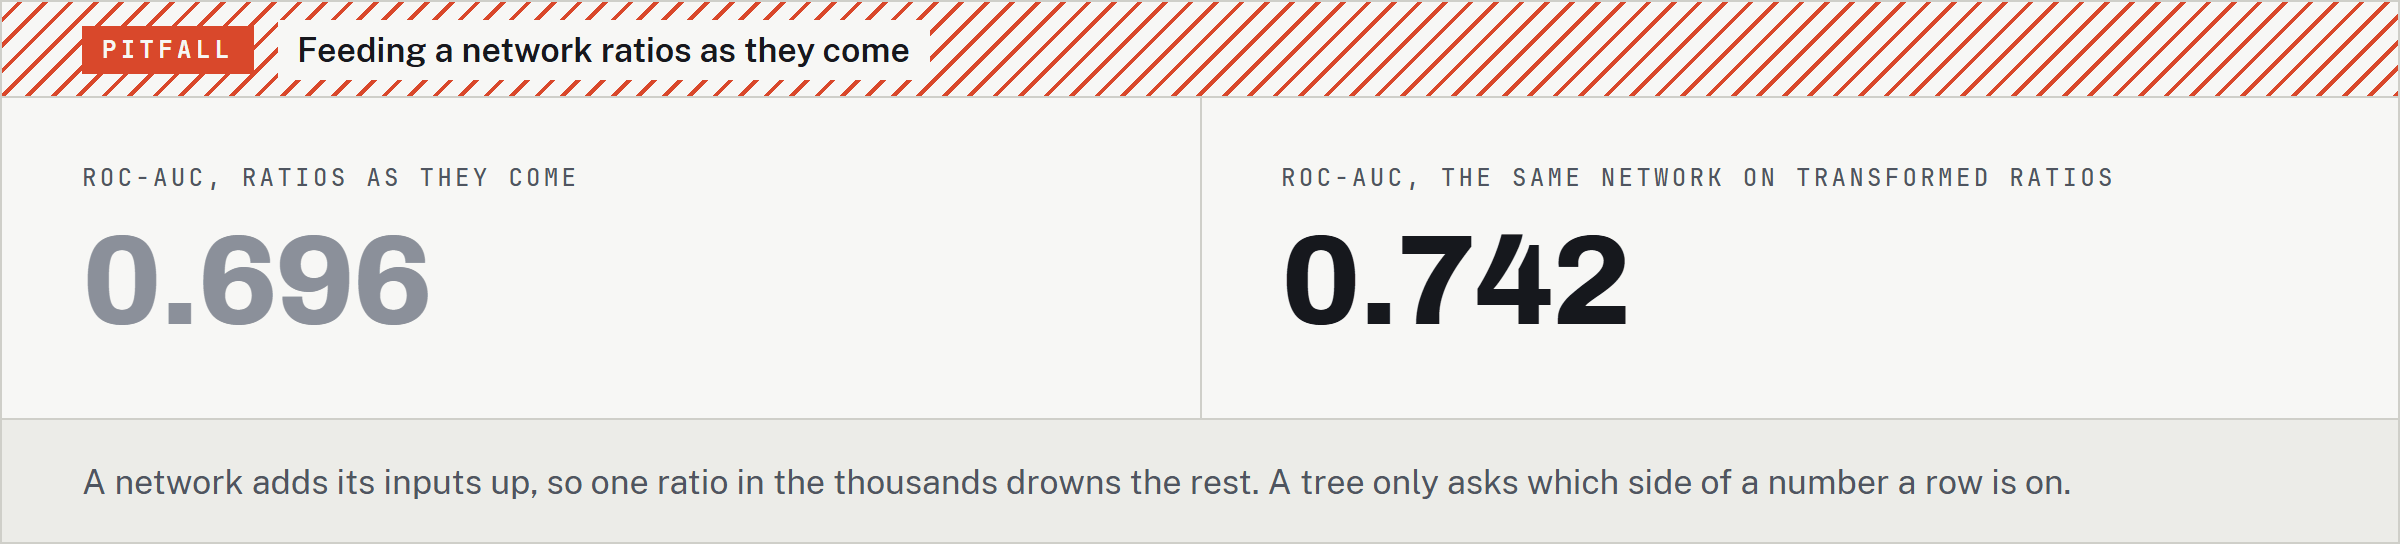)

**Reading.** Fed the ratios as they come, the same network scores 0.696.
That is below the 0.704 of the published Altman Z, a score with five ratios and fixed weights.

The chapter builds one more network, so a rule must say which of the two goes on the ladder.
It is the rule of Chapter 5: the higher mean average precision over the seven folds, each fold counting the same.

**Next, a network that reads more than one year.**

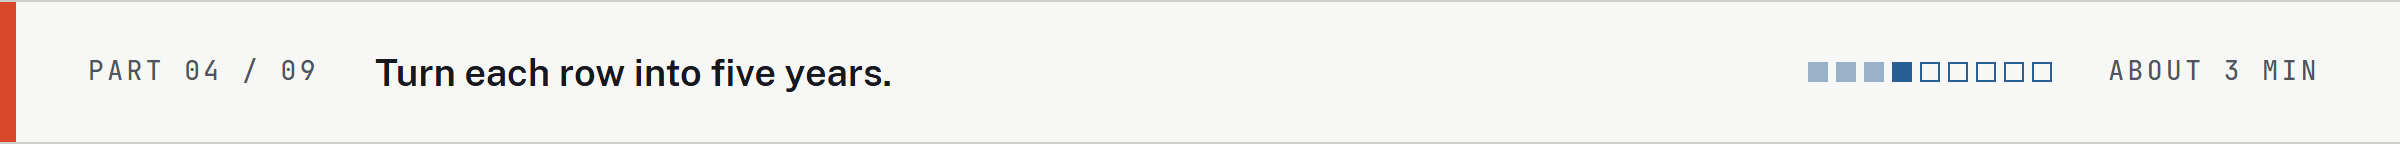

# From Rows to Sequences

Every model so far has read one firm-year at a time.
A **sequence** hands the model a company's last five years together, oldest first.

Not every company has five years to give.
A young company has fewer, and Chapter 1 found companies with gaps in their filings.

So each sequence comes with a **mask**: one where the company filed that year, zero where it did not.
A masked year holds zeros and the model is told to ignore it.

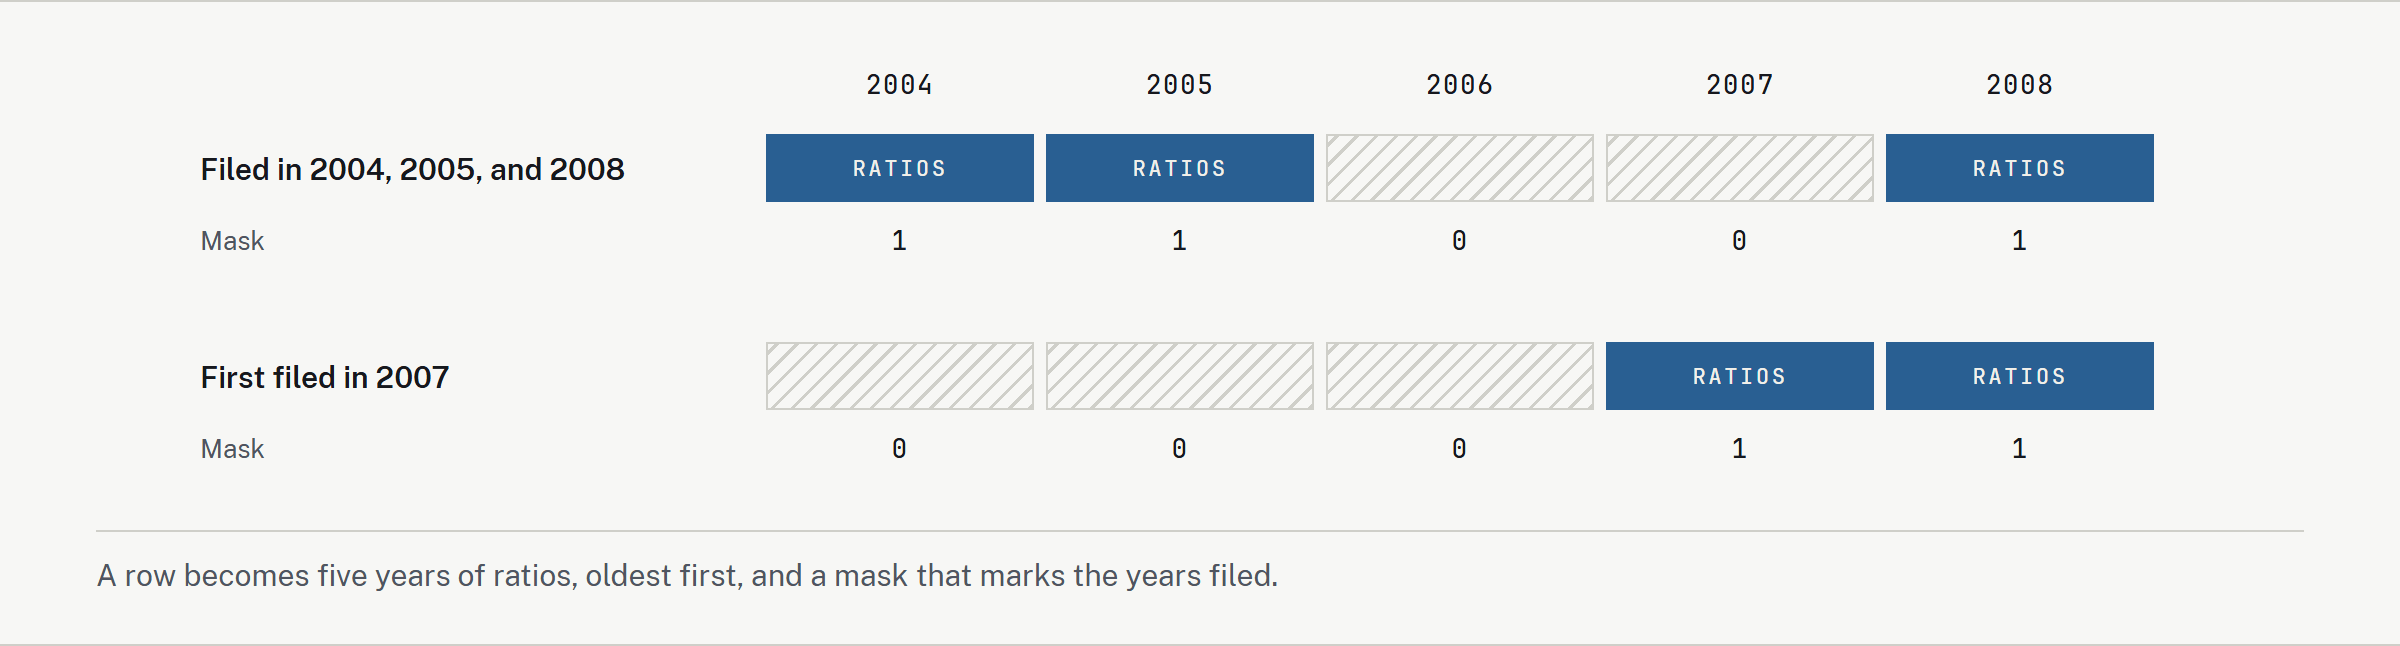

The function that builds the sequences finds each year by the calendar, as `add_history` did in Chapter 3.

In [14]:
# taught: corp_default.nets.build_sequences
def build_sequences(
    frame: pd.DataFrame, cols: list[str], window: int = 5
) -> tuple[np.ndarray, np.ndarray]:
    """Each row's last `window` calendar years of `cols`, oldest first, and a mask of the years filed.

    Returns values of shape (rows, window, cols) and a mask of shape (rows, window). A year the
    company did not file, or a year before its first, is a masked step holding zeros. Steps are
    found by (company_name, year), never by position, so a window never crosses a company.
    """
    keys = ["company_name", "year"]
    if frame.duplicated(keys).any():
        raise ValueError("build_sequences needs one row per (company_name, year)")
    by_key = frame.set_index(keys)[cols]
    values = np.zeros((len(frame), window, len(cols)), dtype=np.float32)
    mask = np.zeros((len(frame), window), dtype=bool)
    for step in range(window):
        years_back = window - 1 - step
        earlier = pd.MultiIndex.from_arrays([frame["company_name"], frame["year"] - years_back])
        filed = earlier.isin(by_key.index)
        mask[:, step] = filed
        values[filed, step] = by_key.reindex(earlier[filed]).to_numpy()
    return values, mask

**Reading.** For each step of the window the function looks up the same company a fixed number of years back.
Where that year was filed it copies the values in, and elsewhere it leaves zeros and a mask of zero.

**Predict 2.** Of the firm-years in the development sample, what share have all five years on file: nearer a quarter, a half, or three quarters?

Q. What do the sequences of the development sample look like?

In [15]:
WINDOW = 5
values, mask = build_sequences(dev, RATIOS, WINDOW)
filed = mask.sum(axis=1)
# A gap shows as a masked step between two filed ones. The first such row is printed.
gap_row = int(np.argmax(mask[:, 0] & ~mask[:, 1:-1].all(axis=1)))
# Every row's own year is its last step, and it is always filed. Checked here.
assert mask[:, -1].all()

store.put("window", WINDOW)
store.put("full_share", (filed == WINDOW).mean())
store.put("one_share", (filed == 1).mean())
store.put("masked_share", 1 - mask.mean())
store.put("gap_year", int(dev.loc[gap_row, "year"]))

print(values.shape, mask.shape)
print(dev.loc[gap_row, KEYS].to_dict(), mask[gap_row].astype(int))
pd.Series(filed).value_counts(normalize=True).sort_index().round(3).to_frame("share of firm-years")

(55524, 5, 24) (55524, 5)
{'company_name': 'C_3', 'year': 2004} [1 1 1 0 1]


,share of firm-years
1,0.140
2,0.127
3,0.113
4,0.108
5,0.511


**Reading.** 51% of firm-years have all five years on file, which answers Predict 2.
14% have only their own year, and 26% of all the steps are masked.

The row printed is from 2004, and its mask shows a gap between two filed years.

**Next, a network that reads the steps in order.**

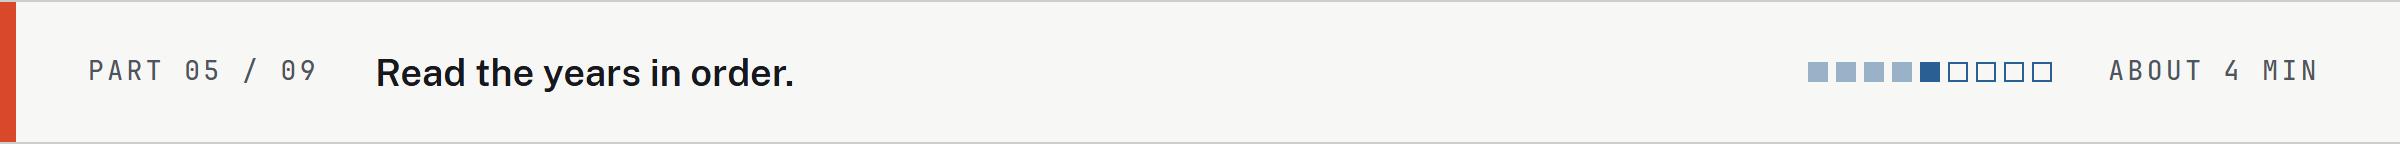

# A Recurrent Network

A **recurrent network** reads a sequence one step at a time and keeps a running summary, its **state**.
At each step it mixes the new year's ratios into the state, and a **GRU** is one well-tried way of doing the mixing.

After the last step the model averages its states over the years that were filed.
From that average it gives three numbers, one for each of the next three years.

In [16]:
# taught: corp_default.nets.SequenceHazardNet
class SequenceHazardNet(nn.Module):
    """A GRU over a company's years, pooled over the years it filed, with one hazard logit a horizon."""

    def __init__(self, n_inputs: int, hidden: int = 32, horizons: int = 3, dropout: float = 0.2):
        super().__init__()
        self.gru = nn.GRU(n_inputs, hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, horizons)

    def forward(self, x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        filed = mask.unsqueeze(-1).to(x.dtype)
        states, _ = self.gru(x * filed)
        pooled = (states * filed).sum(dim=1) / filed.sum(dim=1)
        return self.head(self.dropout(pooled))

**Reading.** `forward` multiplies the inputs and the states by the mask, so a masked year adds nothing to the average.
The last layer, `head`, turns the average into three numbers.

Each of the three is a **hazard**: the chance that the final filing falls in that year, given that it has not come sooner.
The first year's hazard is asked of every row, and the second only of rows that did not fail in the first.

The third has one more condition.
A fold may only use final filings up to the year before its validation year, so a training row whose third year runs past that edge is not asked about it.

The library's `hazard_loss` is the loss the training loop already uses: it averages over the questions that were asked and gives the rest no weight.

Q. What does the recurrent network score on the walk-forward?

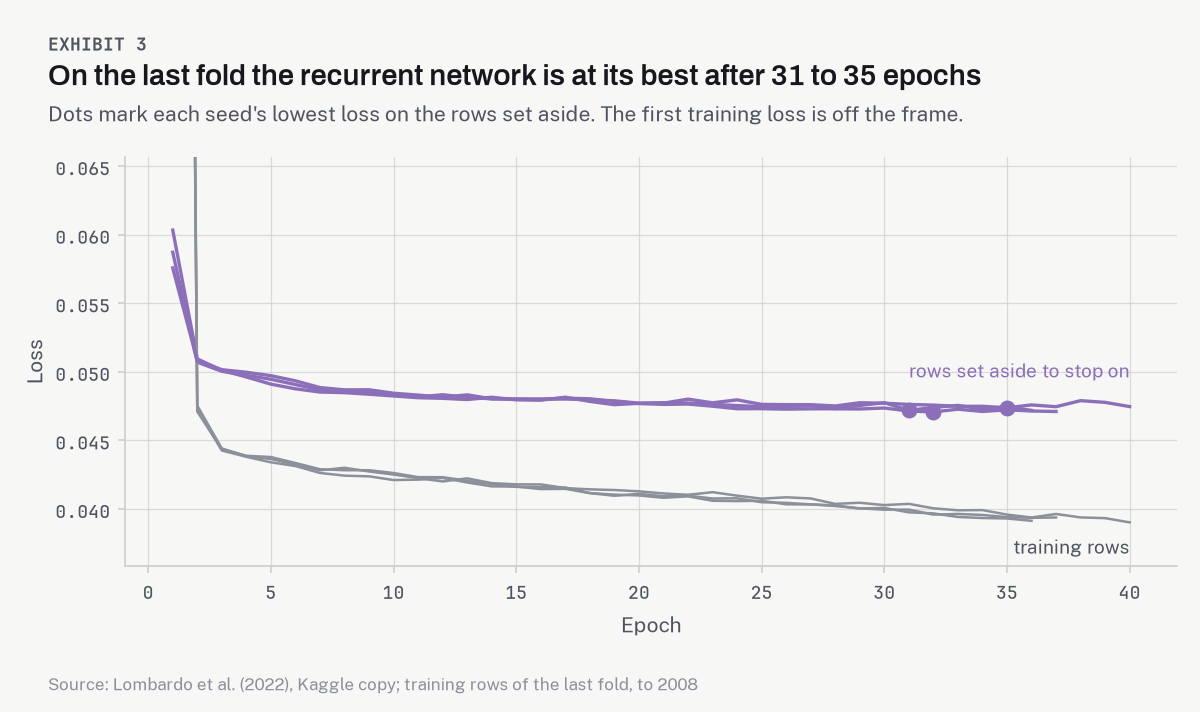

In [17]:
def hazard_targets(rows: pd.DataFrame, known_to: int) -> tuple[torch.Tensor, torch.Tensor]:
    """Three hazard targets for each row, and which of them are asked, with final filings known to `known_to`."""
    happened = np.column_stack(
        [rows["target_1"], rows["target"] - rows["target_1"], rows["target_3"] - rows["target"]]
    )
    asked = np.column_stack(
        [
            np.ones(len(rows), dtype=bool),
            rows["target_1"] == 0,
            (rows["target"] == 0) & (rows["year"] + 3 <= known_to),
        ]
    )
    return tensor(np.where(asked, happened, 0.0)), tensor(asked)


def sequence_fit(fold, seed: int) -> dict:
    """One recurrent network for one fold and one seed."""
    train = dev.loc[fold.train]
    # Sequences reach back through the gap years before the fold. Those years lend ratios, never labels.
    seen = dev.loc[dev["year"] <= fold.year]
    inputs = fit_inputs(train, RATIOS)(seen)
    values, mask = build_sequences(inputs.join(seen[KEYS]), list(inputs.columns), WINDOW)
    at = pd.Series(np.arange(len(seen)), index=seen.index)
    rows_train, rows_valid = at.loc[fold.train].to_numpy(), at.loc[fold.valid].to_numpy()
    data = (
        tensor(values[rows_train]),
        torch.tensor(mask[rows_train]),
        *hazard_targets(train, known_to=fold.year - 1),
    )
    valid_inputs = (tensor(values[rows_valid]), torch.tensor(mask[rows_valid]))
    width = values.shape[2]
    return fit_net(
        lambda: SequenceHazardNet(width), data, stop_rows(train), valid_inputs, seed, SETTINGS["lr"]
    )


_, asked_last = hazard_targets(train_last, known_to=last.year - 1)
latest = torch.tensor((train_last["year"] == train_last["year"].max()).to_numpy())
# No row of the last training year is asked about its third year. Checked here.
assert asked_last[latest, 2].sum() == 0 and asked_last[~latest, 2].sum() > 0
# hazard_loss ignores a question that was not asked. Checked here on made-up numbers.
assert hazard_loss(torch.zeros(1, 2), torch.tensor([[0.0, 1.0]]), torch.tensor([[1.0, 0.0]])) == (
    hazard_loss(torch.zeros(1, 2), torch.tensor([[0.0, 0.0]]), torch.tensor([[1.0, 0.0]]))
)

# This cell is the slowest of the chapter: 21 recurrent networks, twice each. Allow several minutes.
seq_fits = side_by_side(sequence_fit)
hazards = seed_mean(seq_fits)
seq_last = last_fold_epochs(seq_fits)

store.put("seq_last_low", seq_last[0])
store.put("seq_last_high", seq_last[-1])
# The reading says the recurrent network trains for longer than the tabular one. Checked here.
assert seq_fits["epochs"].median() > tab_fits["epochs"].median()

viz.exhibit(
    learning_curves(seq_fits),
    f"On the last fold the recurrent network is at its best after {seq_last[0]} to {seq_last[-1]} epochs",
    "Dots mark each seed's lowest loss on the rows set aside. The first training loss is off the frame.",
    f"{SOURCE}; training rows of the last fold, to {train_last['year'].max()}",
)

**Reading.** Exhibit 3 has the shape of Exhibit 2, stretched: the recurrent network takes 31 to 35 epochs to reach its low on the last fold.
It has three questions to learn and a sequence to read, and it learns them more slowly.

**Next, what the three hazards say together.**

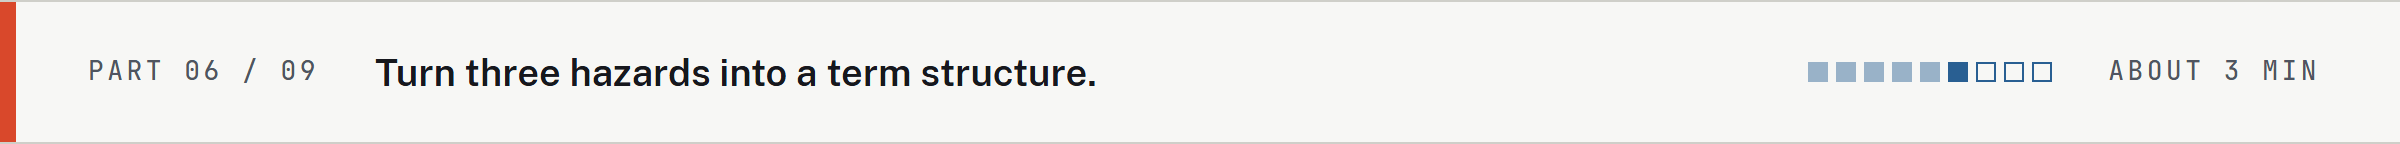

# One Model, Three Horizons

Three hazards chain into a **term structure**: the probability of failing within one year, within two, and within three.
To survive two years a company must survive the first and then the second, so the survival chances multiply.

In [18]:
# taught: corp_default.nets.cumulative_pd
def cumulative_pd(hazards: np.ndarray) -> np.ndarray:
    """Probability of failing within each horizon, from the hazard of each year given survival to it."""
    return 1 - np.cumprod(1 - hazards, axis=-1)

**Reading.** One minus each hazard is the chance of getting through that year, the running product is the chance of getting through all the years so far, and one minus that is the cumulative probability of default.

The ladder is built on the two-year label, so the recurrent network's score for the ladder is its two-year probability.

The three-year outcome is compared only on rows up to 2010.
A three-year label on a later row would reach into the years this casebook keeps sealed until Chapter 7.

Q. Does the term structure match what happened, from the safest tenth of firm-years to the riskiest?

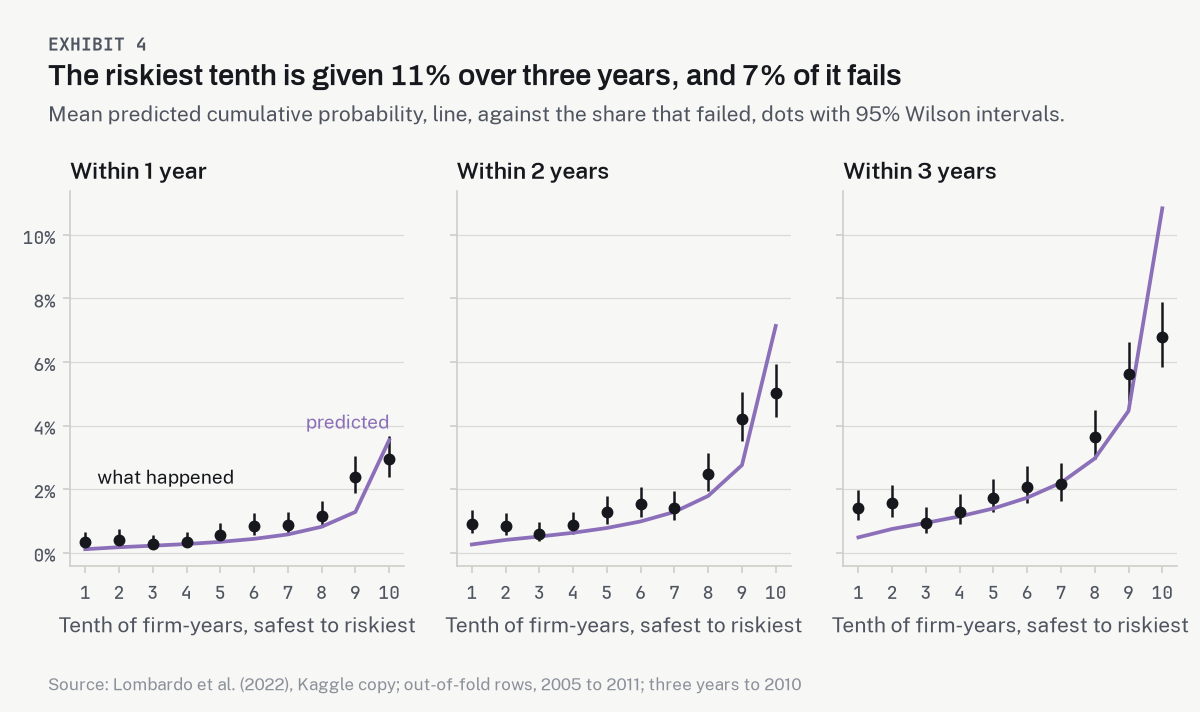

In [19]:
pds = cumulative_pd(hazards)
seq_oof = as_oof(pds[:, HORIZON - 1])
outcomes = dev.loc[np.concatenate([fold.valid for fold in folds])].reset_index(drop=True)
LAST_3Y = DEV_END + HORIZON - 3  # the last year whose three-year label stays inside the embargo
realised = pd.DataFrame(
    {
        1: outcomes["target_1"],
        2: outcomes["target"],
        3: outcomes["target_3"].where(outcomes["year"] <= LAST_3Y),
    }
)
tenth = pd.qcut(seq_oof["pct"].rank(method="first"), 10, labels=range(1, 11))

fig, axes = plt.subplots(1, 3, figsize=(viz.EXHIBIT_WIDTH_IN, 3.4), sharey=True)
horizon_auc = {}
for ax, years in zip(axes, realised):
    known = realised[years].notna()
    predicted = pd.Series(pds[:, years - 1])[known].groupby(tenth[known], observed=True).mean()
    failed = realised.loc[known, years].groupby(tenth[known], observed=True).agg(["sum", "count"])
    bounds = np.array([wilson_interval(int(k), int(n)) for k, n in failed.to_numpy()])
    rate = failed["sum"] / failed["count"]
    ax.vlines(rate.index.astype(int), bounds[:, 0], bounds[:, 1], color=viz.INK, linewidth=1.2)
    ax.scatter(rate.index.astype(int), rate, s=22, color=viz.INK, zorder=3)
    ax.plot(predicted.index.astype(int), predicted, color=NETWORKS, linewidth=1.8)
    ax.set_title(f"Within {years} year{'s' if years > 1 else ''}")
    ax.set_xlabel("Tenth of firm-years, safest to riskiest")
    ax.set_xticks(range(1, 11))
    ax.grid(axis="x", visible=False)
    horizon_auc[years] = roc_auc_score(
        realised.loc[known, years],
        within_year_percentile(pd.Series(pds[:, years - 1])[known], outcomes.loc[known, "year"]),
    )
    if years == 3:
        store.put("top_pd_3", predicted.iloc[-1])
        store.put("top_rate_3", rate.iloc[-1])
        store.put("bottom_pd_3", predicted.iloc[0])
        store.put("bottom_rate_3", rate.iloc[0])
        top_pd, top_rate = predicted.iloc[-1], rate.iloc[-1]
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].annotate("predicted", (10, top_pd * 0.36), color=NETWORKS, size=9, ha="right")
axes[0].annotate("what happened", (5.4, top_pd * 0.2), color=viz.INK, size=9, ha="right")

# The readings say the top tenth is predicted too high, the bottom too low, and ranking fades with the horizon.
assert top_pd > top_rate and predicted.iloc[0] < rate.iloc[0]
assert horizon_auc[1] > horizon_auc[2] > horizon_auc[3]
for years, value in horizon_auc.items():
    store.put(f"horizon_auc_{years}", value)
store.put("last_3y_year", LAST_3Y)

viz.exhibit(
    fig,
    f"The riskiest tenth is given {top_pd:.0%} over three years, and {top_rate:.0%} of it fails",
    "Mean predicted cumulative probability, line, against the share that failed, dots with 95% "
    "Wilson intervals.",
    OOF_SOURCE + f"; three years to {LAST_3Y}",
)

**Reading.** In Exhibit 4 the predicted line rises with the horizon and with the tenth, as a term structure should.
It is too steep: over three years the riskiest tenth is given 10.8% and fails at 6.8%, and the safest is given 0.5% and fails at 1.4%.

The ranking is strongest at one year and fades: ROC-AUC 0.724, 0.696, and 0.679 at one, two, and three years.

**Next, the networks beside the trees.**

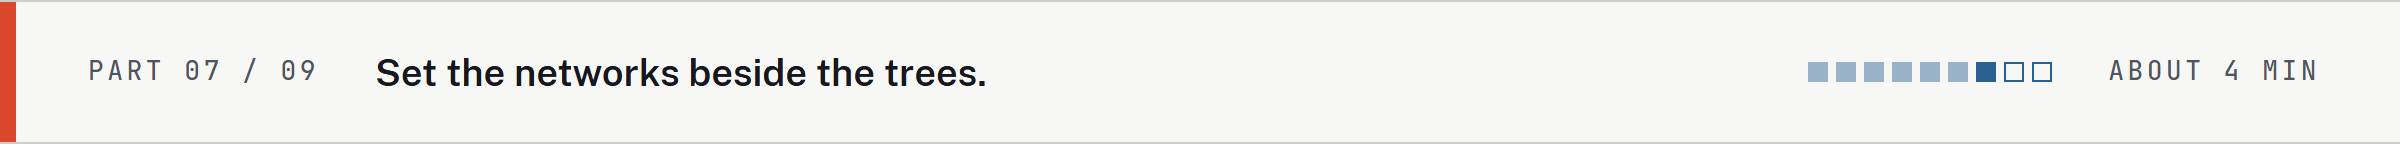

# Trees Against Networks

Three models have now read the same 24 ratios on the same folds: the trees of Chapter 5, the tabular network, and the recurrent network.
Only the last was shown more than one year of each company.

Q. Which ranks best, and which network goes on the ladder?

In [20]:
models = {TREES: ladder[TREES], "Tabular network": tab_oof, "Recurrent network": seq_oof}
versus = pd.DataFrame(
    {
        name: {
            "ROC-AUC": roc_auc_score(oof["target"], oof["pct"]),
            "average precision": average_precision_score(oof["target"], oof["pct"]),
            "mean average precision, seven folds": mean_fold_ap(oof),
        }
        for name, oof in models.items()
    }
).T
seq_step = step("Tabular network", "Recurrent network", models)
networks = versus.drop(index=TREES)["mean average precision, seven folds"]
best_network = networks.idxmax()
# The readings say the tabular network goes on the ladder and the recurrent one ranks below it.
assert best_network == "Tabular network"
assert seq_step["roc_auc_diff_hi"] < 0

store.put("seq_auc", versus.loc["Recurrent network", "ROC-AUC"])
store.put("seq_step", seq_step["roc_auc_diff"])
store.put("seq_step_low", seq_step["roc_auc_diff_lo"])
store.put("seq_step_high", seq_step["roc_auc_diff_hi"])
store.put("tab_fold_ap", networks["Tabular network"])
store.put("seq_fold_ap", networks["Recurrent network"])

versus.round(4)

,ROC-AUC,average precision,"mean average precision, seven folds"
"All ratios, trees",0.7755,0.0690,0.0795
Tabular network,0.7422,0.0621,0.0711
Recurrent network,0.6956,0.0425,0.0465


**Reading.** The recurrent network scores 0.696, and its paired difference from the tabular network is -0.047, with an interval from -0.071 to -0.020.
So on this walk-forward the answer to the chapter's question is no: handed the years in order, the network ranks worse than the one that saw a single year.

By the rule, the tabular network goes on the ladder, at 0.0711 against 0.0465.

Trees ahead of networks on a table of numbers is a common result.
Two studies of many tabular datasets report it: [Grinsztajn, Oyallon, and Varoquaux (2022)](https://doi.org/10.52202/068431-0037) and [Shwartz-Ziv and Armon (2022)](https://doi.org/10.1016/j.inffus.2021.11.011).

A lower score does not make a model useless beside a higher one.
What matters for a blend is whether the two are wrong about different companies.

Q. Where do the trees and the network disagree?

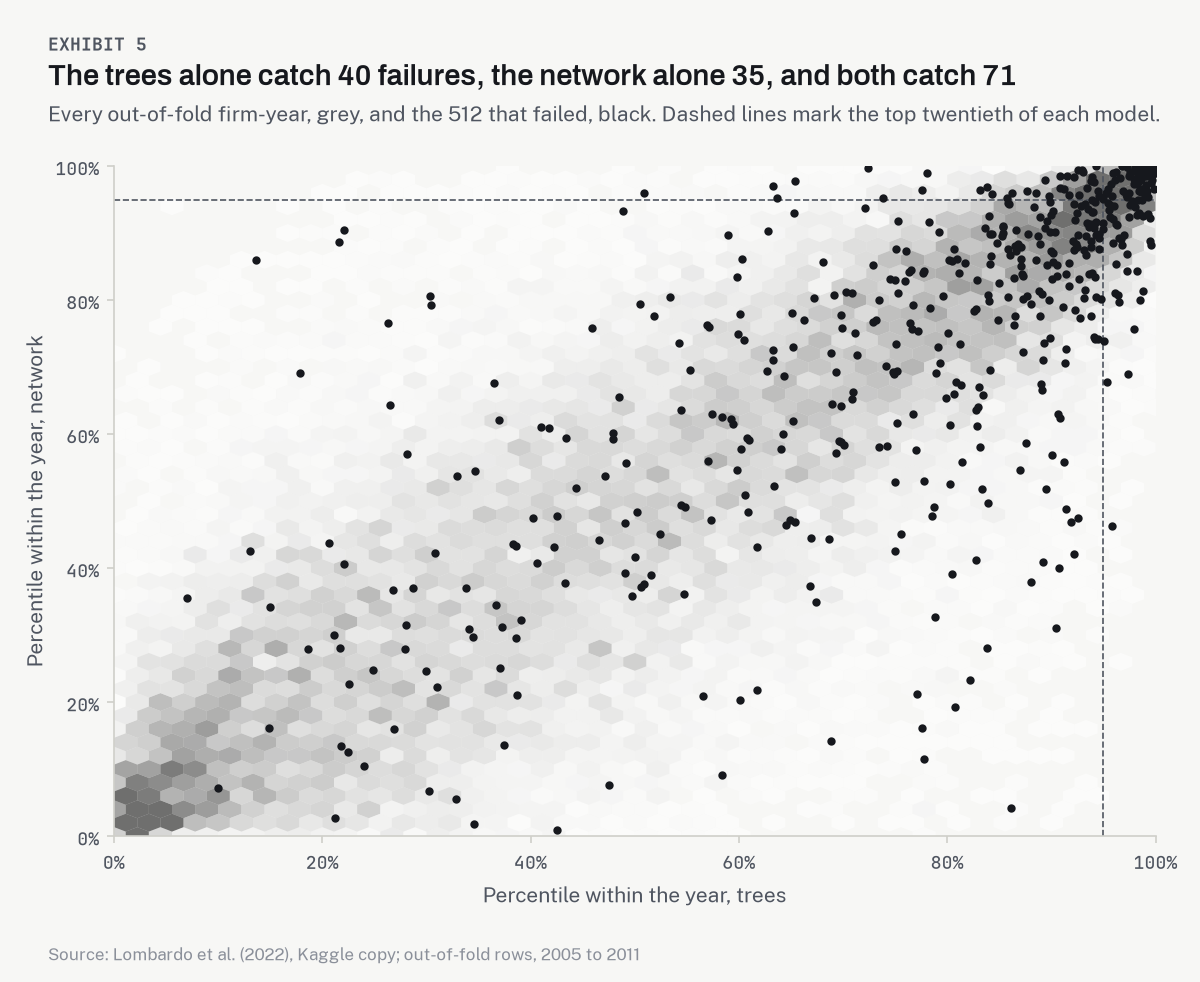

In [21]:
BUDGET = 0.05  # the middle review budget: the top twentieth of each year
tree_pct, net_pct = ladder[TREES]["pct"], tab_oof["pct"]
failures = (oof_rows["target"] == 1).to_numpy()
tree_flags, net_flags = (tree_pct > 1 - BUDGET).to_numpy(), (net_pct > 1 - BUDGET).to_numpy()
caught = {
    "both": int((failures & tree_flags & net_flags).sum()),
    "trees only": int((failures & tree_flags & ~net_flags).sum()),
    "network only": int((failures & ~tree_flags & net_flags).sum()),
}
rank_correlation = tree_pct.corr(net_pct, method="spearman")

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 5.2))
ax.hexbin(tree_pct, net_pct, gridsize=45, cmap="Greys", vmax=60, linewidths=0, mincnt=1, alpha=0.55)
ax.scatter(tree_pct[failures], net_pct[failures], s=9, color=viz.INK, zorder=3)
ax.axvline(1 - BUDGET, color=viz.SLATE, linewidth=0.8, linestyle="--")
ax.axhline(1 - BUDGET, color=viz.SLATE, linewidth=0.8, linestyle="--")
ax.set_xlabel("Percentile within the year, trees")
ax.set_ylabel("Percentile within the year, network")
ax.set_xlim(0, 1.0)
ax.set_ylim(0, 1.0)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(visible=False)

store.put("rank_correlation", rank_correlation)
store.put("n_failures", int(failures.sum()))
for name, count in caught.items():
    store.put("caught_" + name.replace(" ", "_"), count)
# The reading says each model catches failures the other misses. Checked here.
assert caught["trees only"] > 0 and caught["network only"] > 0

viz.exhibit(
    fig,
    f"The trees alone catch {caught['trees only']} failures, the network alone "
    f"{caught['network only']}, and both catch {caught['both']}",
    f"Every out-of-fold firm-year, grey, and the {int(failures.sum())} that failed, black. Dashed "
    "lines mark the top twentieth of each model.",
    OOF_SOURCE,
    save_as="ch6",
)

**Reading.** In Exhibit 5 a firm-year on the diagonal is ranked the same by both models, and the rank correlation is 0.79.
Of the 512 failures, both models put 71 in their top twentieth.

The trees alone catch 40 more, and the network alone 35.
The two models disagree, and each is sometimes right where the other is wrong.

**Next, whether the disagreement can be put to use.**

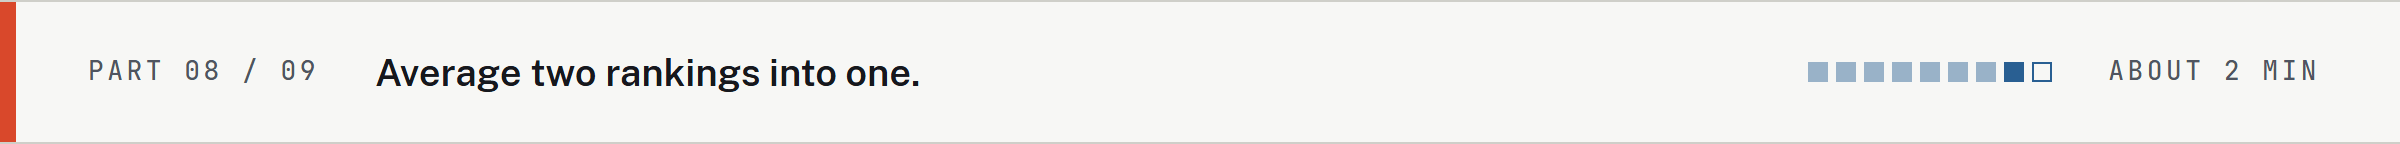

# Blending

A **blend** combines the scores of two models into one.
The simplest blend, and the one used here, averages each firm-year's two percentiles within its year.

No weight is fitted, so there is nothing for the blend to learn from the validation rows.

Q. Does the blend rank better than the trees alone?

In [22]:
blend_oof = as_oof(((tree_pct + net_pct) / 2).to_numpy())
models[BLEND] = blend_oof
blend_step = step(TREES, BLEND, models)
blend_board = scoreboard({TREES: ladder[TREES], BLEND: blend_oof}).set_index("model")
# The reading says the blend and the trees cannot be told apart. Checked here.
assert blend_step["roc_auc_diff_lo"] < 0 < blend_step["roc_auc_diff_hi"]
assert blend_step["ap_diff_lo"] < 0 < blend_step["ap_diff_hi"]

store.put("blend_auc", blend_board.loc[BLEND, "roc_auc"])
store.put("blend_step", blend_step["roc_auc_diff"])
store.put("blend_step_low", blend_step["roc_auc_diff_lo"])
store.put("blend_step_high", blend_step["roc_auc_diff_hi"])
store.put("blend_ap_step", blend_step["ap_diff"])
store.put("blend_ap_step_low", blend_step["ap_diff_lo"])
store.put("blend_ap_step_high", blend_step["ap_diff_hi"])
store.put("blend_capture_5", blend_board.loc[BLEND, "capture_5"])
store.put("trees_capture_5", blend_board.loc[TREES, "capture_5"])

blend_board[["roc_auc", "roc_auc_lo", "roc_auc_hi", "ap", "capture_5", "lift_5"]].round(3)

,roc_auc,roc_auc_lo,roc_auc_hi,ap,capture_5,lift_5
model,,,,,,
"All ratios, trees",0.776,0.752,0.799,0.069,0.217,4.337
"Blend, trees and network",0.771,0.748,0.794,0.072,0.221,4.416


**Reading.** The blend scores 0.771.
Against the trees alone the paired difference in ROC-AUC is -0.005, with an interval from -0.014 to 0.005.

In average precision it is 0.0030, from -0.0037 to 0.0122.
Both intervals hold zero, so on this evidence the blend and the trees cannot be told apart.

At the middle budget the blend finds 22.1% of the failures and the trees 21.7%.

**Check.** Why average the two models' percentiles, and not their probabilities?

<details>
<summary>Show the answer</summary>

The two models' probabilities are on different scales, and neither has been calibrated yet.
An average of probabilities would be led by whichever model spreads its numbers wider.

A percentile puts both on the same scale, and it is the scale the ladder is scored on.

</details>

**Next, the seven rungs together.**

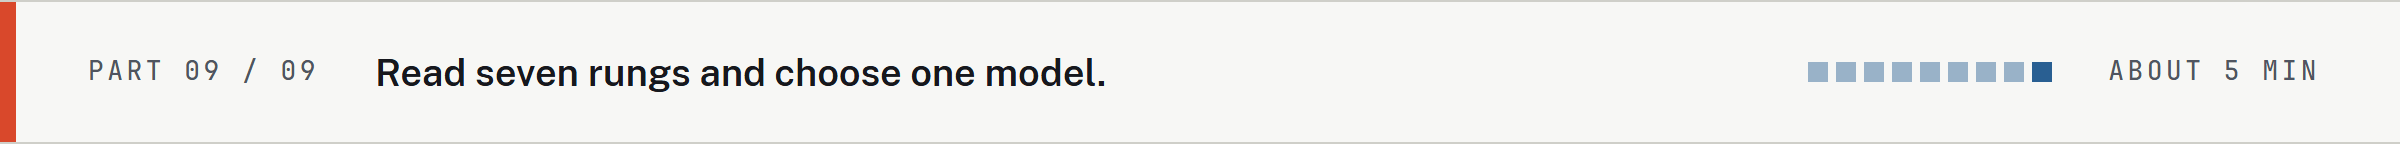

# The Ladder So Far

The ladder gets its last two rungs: the network, and the blend of the network with the trees.

Q. What do the seven rungs score, and what does each add to the one below?

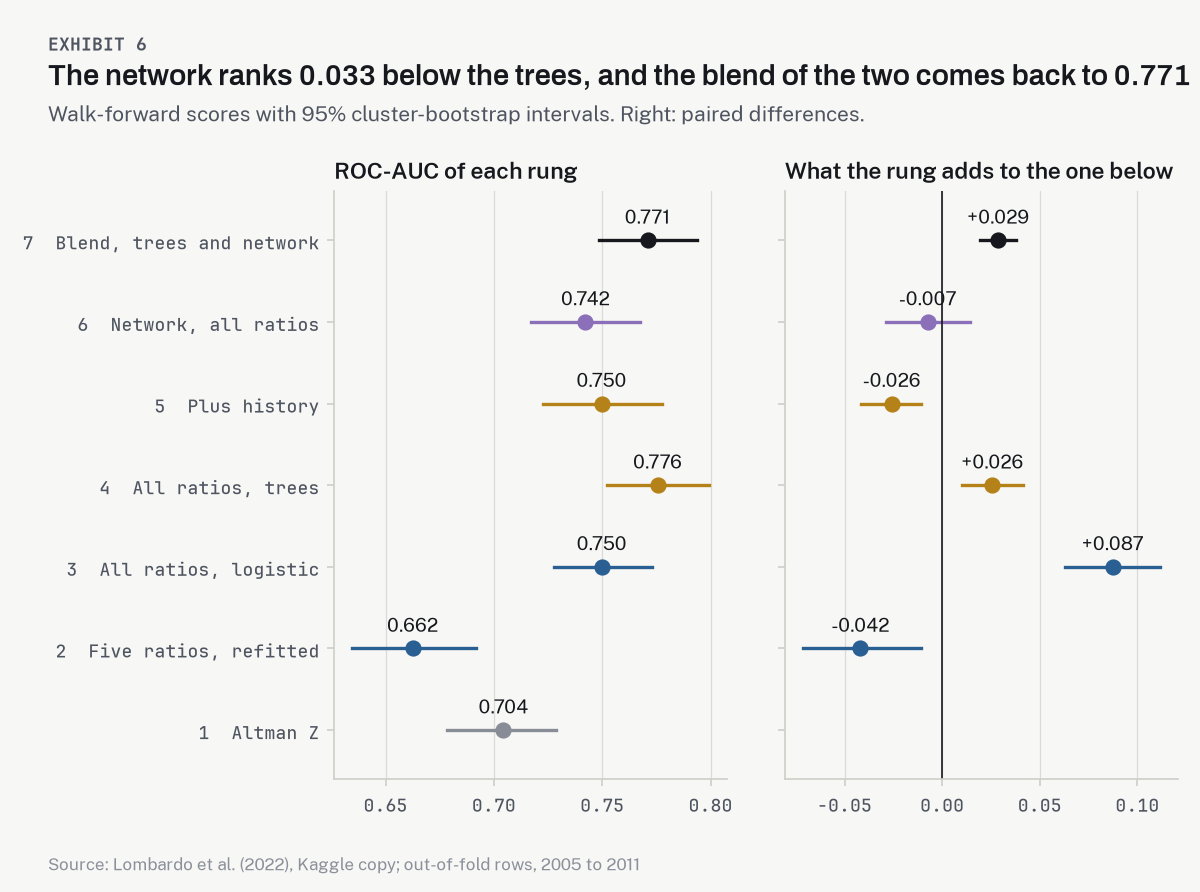

In [23]:
ladder[NETWORK], ladder[BLEND] = tab_oof, blend_oof
board = scoreboard(ladder).set_index("model")
steps = paired_table(ladder, list(ladder)).set_index("model")

KINDS = ("classic", "logistic", "logistic", "trees", "trees", "networks", "blend")
COLORS = [viz.MODEL_COLORS[kind] for kind in KINDS]
fig, (level, change) = plt.subplots(1, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 4.6), sharey=True)
place = np.arange(len(ladder))
for y_at, (name, row), color in zip(place, board.iterrows(), COLORS):
    level.plot([row["roc_auc_lo"], row["roc_auc_hi"]], [y_at, y_at], color=color, linewidth=1.6)
    level.scatter(row["roc_auc"], y_at, s=46, color=color, zorder=3)
    level.annotate(f"{row['roc_auc']:.3f}", (row["roc_auc"], y_at), xytext=(0, 8),
                   textcoords="offset points", ha="center", size=9)  # fmt: skip
for y_at, (name, row), color in zip(place[1:], steps.iterrows(), COLORS[1:]):
    change.plot([row["roc_auc_diff_lo"], row["roc_auc_diff_hi"]], [y_at, y_at], color=color,
                linewidth=1.6)  # fmt: skip
    change.scatter(row["roc_auc_diff"], y_at, s=46, color=color, zorder=3)
    change.annotate(f"{row['roc_auc_diff']:+.3f}", (row["roc_auc_diff"], y_at), xytext=(0, 8),
                    textcoords="offset points", ha="center", size=9)  # fmt: skip
change.axvline(0, color=viz.INK, linewidth=0.8)
level.set_yticks(place, [f"{k + 1}  {name}" for k, name in enumerate(ladder)])
level.set_ylim(-0.6, len(ladder) - 0.4)
level.set_title("ROC-AUC of each rung")
level.xaxis.set_major_locator(MultipleLocator(0.05))
change.set_title("What the rung adds to the one below")
for ax in (level, change):
    ax.grid(axis="y", visible=False)

store.put("network_step", steps.loc[NETWORK, "roc_auc_diff"])
store.put("top_step", steps.loc[BLEND, "roc_auc_diff"])
# The reading says the fourth rung is still the highest. Checked here.
assert board["roc_auc"].idxmax() == TREES

viz.exhibit(
    fig,
    f"The network ranks {-tab_step['roc_auc_diff']:.3f} below the trees, and the blend of the two "
    f"comes back to {board.loc[BLEND, 'roc_auc']:.3f}",
    "Walk-forward scores with 95% cluster-bootstrap intervals. Right: paired differences.",
    OOF_SOURCE,
)

**Reading.** Exhibit 6 is the ladder with all seven rungs.
The sixth rung, the network, differs from the fifth by -0.007, and the seventh, the blend, adds 0.029 to the sixth.

The fourth rung is still the highest in ROC-AUC.
Nothing built since the trees first read the ratios has ranked above them.

One model must be named before the holdout is opened.
The candidates are the tree model, the network, and the blend, and the first test is the one used all along: the highest mean average precision over the seven folds.

A second test guards against complexity that buys nothing.
A blend must beat its simplest member with a paired interval above zero, or the simpler model stands.

This second test was added after the first test's result was seen, and before the holdout was opened.

Q. Which model do the two tests name?

In [24]:
finalists = pd.Series({name: mean_fold_ap(ladder[name]) for name in (TREES, NETWORK, BLEND)})
finalists = finalists.sort_values(ascending=False)
leader = finalists.index[0]
# The blend is two models. It is named only if its gain over the trees alone has an interval above zero.
chosen = TREES if leader == BLEND and blend_step["ap_diff_lo"] <= 0 else leader
chosen_folds = fold_table(ladder[chosen]).set_index("fold")
crisis, calm = chosen_folds.loc["crisis folds"], chosen_folds.loc["calm folds"]
# The readings say the blend leads by less than a seed moves the network, the trees are named, and the folds overlap.
assert leader == BLEND and finalists.index[1] == TREES and chosen == TREES
assert finalists.iloc[0] - finalists.iloc[1] < max(one_seed) - min(one_seed)
assert crisis["roc_auc_hi"] > calm["roc_auc_lo"]

store.put("chosen_ap", finalists.iloc[0])
store.put("runner_up_ap", finalists.iloc[1])
store.put("crisis_auc", crisis["roc_auc"])
store.put("crisis_auc_low", crisis["roc_auc_lo"])
store.put("crisis_auc_high", crisis["roc_auc_hi"])
store.put("calm_auc", calm["roc_auc"])
store.put("calm_auc_low", calm["roc_auc_lo"])
store.put("calm_auc_high", calm["roc_auc_hi"])

print(finalists.round(4).to_frame("mean average precision, seven folds"))
chosen_folds[["rows", "positives", "roc_auc", "roc_auc_lo", "roc_auc_hi", "capture_5"]].round(3)

                          mean average precision, seven folds
Blend, trees and network                               0.0801
All ratios, trees                                      0.0795
Network, all ratios                                    0.0711


,rows,positives,roc_auc,roc_auc_lo,roc_auc_hi,capture_5
fold,,,,,,
2005,4165,105,0.729,0.680,0.776,0.162
2006,4077,114,0.767,0.725,0.810,0.228
2007,3950,79,0.816,0.762,0.858,0.266
2008,3799,57,0.760,0.701,0.816,0.211
2009,3720,59,0.765,0.703,0.819,0.169
2010,3590,47,0.827,0.780,0.874,0.213
2011,3488,51,0.811,0.753,0.862,0.294
crisis folds,12192,298,0.767,0.733,0.799,0.215
calm folds,14597,214,0.788,0.756,0.822,0.220


**Reading.** The blend has the highest mean average precision, at 0.0801 against 0.0795 for the trees alone.
The margin is far smaller than the 0.0110 by which the network's own score moves from one seed to another, and the blend's paired interval over the trees holds zero.

So the second test decides, and the simpler model stands: the tree model of Chapter 5 is the one named.

It ranks at 0.767 in the crisis folds, with an interval from 0.733 to 0.799.
In the calm folds it ranks at 0.788, from 0.756 to 0.822, so the two intervals overlap.

Q. What does the chapter hand on?

In [25]:
oof_scores = pd.concat(
    [earlier, *(ladder[name].assign(model=name) for name in NEW)], ignore_index=True
)
frozen = {name: spec for name, spec in frozen.items() if name not in NEW}
frozen[NETWORK] = {
    "kind": "tabular network",
    "features": RATIOS,
    "inputs": "quantile transform to a normal scale, blanks at zero, a flag for each ratio with blanks",
    "hidden": 64,
    "dropout": best[1],
    "settings": {**SETTINGS, "lr": best[0]},
    "grid": {"lr": sorted({lr for lr, _ in GRID}), "dropout": sorted({rate for _, rate in GRID})},
    "seeds": list(SEEDS),
    "stop_years": STOP_YEARS,
}
frozen[BLEND] = {"kind": "mean of within-year percentiles", "members": [TREES, NETWORK]}
for name in frozen:
    frozen[name]["chosen"] = name == chosen
store.save_frame("oof_scores", oof_scores)
store.save_json("frozen", frozen)

oof_scores.groupby("model", sort=False)["target"].agg(rows="size", positives="sum")

,rows,positives
model,,
Altman Z,26789,512
"Five ratios, refitted",26789,512
"All ratios, logistic",26789,512
"All ratios, trees",26789,512
Plus history,26789,512
"Network, all ratios",26789,512
"Blend, trees and network",26789,512


**Reading.** The table of scores now holds seven rungs on the same rows, and the record marks the tree model as the one chosen.

Every choice in this casebook was made on those rows.
**The next chapter opens the years none of them has seen.**

# Findings

1. A network needs its inputs on one scale: the same network scores 0.696 on ratios as they come and 0.742 on transformed ones (Exhibit 1).
2. Early stopping on a fold's own last two training years chooses 7 to 13 epochs for the tabular network on the last fold, and the validation year is never touched (Exhibit 2).
3. A grid of 6 pairings of learning rate and dropout chooses the plain settings, and the whole grid spans less than the seed moves one network (Exhibit 2).
4. On the same 24 ratios the tabular network's ROC-AUC differs from the trees' by -0.033, with an interval below zero (Exhibit 6).
5. A recurrent network that reads five years in order ranks lower still, at 0.696: history does not help here in this form either (Exhibit 3).
6. Three hazards give a term structure that rises as it should and is too steep: the riskiest tenth is given 10.8% over three years and fails at 6.8% (Exhibit 4).
7. The trees and the network disagree, with a rank correlation of 0.79, and each catches failures the other misses (Exhibit 5).
8. The blend scores 0.771, and its difference from the trees alone has an interval that holds zero, so the simpler tree model is the one named (Exhibit 6).

# Your Turn

Three extensions, each with a hint folded under it.

**1. More seeds.** The ensemble averages three seeds. Does the tabular network gain from ten?

<details>
<summary>Hint</summary>

Set `SEEDS = tuple(SEED + k for k in range(10))` and run `side_by_side(tabular_fit)` again.
Compare `as_oof(seed_mean(...))` with `tab_oof` through `paired_table`.

</details>

**2. A wider search.** The grid tried the learning rate and dropout only. Does a wider network, or less weight decay, close the gap to the trees?

<details>
<summary>Hint</summary>

`TabularNet` takes `hidden`, and `SETTINGS` holds `weight_decay`.
Pass them through `tabular_fit` as `lr` and `dropout` are passed, score each choice by `mean_fold_ap`, and write the rule down before you look.

</details>

**3. The last state.** The recurrent network averages its states over the years filed. Does it rank better if it keeps only the state of the last year?

<details>
<summary>Hint</summary>

Write a subclass of `SequenceHazardNet` whose `forward` passes `states[:, -1]` to the dropout and the head.
The last step is always a filed year, so no mask is needed there.

</details>

[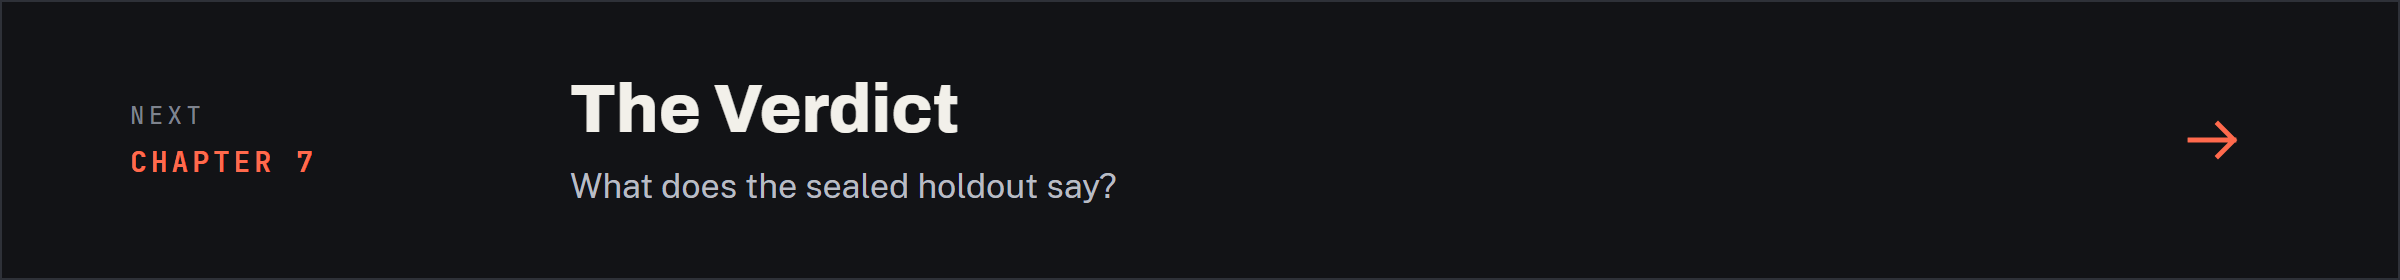](07_the_verdict.ipynb)